# The "Sugar Trap" Market Gap Analysis

**Author:** Emmanuel ASIFIWE · **Client:** Helix CPG Partners · **Data:** Open Food Facts

## The question

*Where is the "Blue Ocean" in the snack aisle?* In other words: which snack categories sell plenty of
products, but almost none that are **low in sugar and high in protein**?

## What this analysis can and cannot say

Open Food Facts is a catalog. It lists what shops and brands **offer**. It does not record what people
**buy**. So a gap in the catalog is a gap on the shelf, not proof that shoppers want the missing product.

For that reason the result is called a **catalog white-space candidate**. The final recommendation names a
category and a nutrition target, and says in the same paragraph what the evidence is and where it stops.

## How to run it

Open the notebook in Google Colab and choose **Runtime ▸ Run all**. The first run downloads a slice of the
Open Food Facts export and saves a copy, so later runs start quickly. Nothing needs to be typed in.

## What is in each section

| # | Section | Brief |
|---|---------|-------|
| 1 | Setup and data | — |
| 2 | Cleaning the data | Story 1 |
| 3 | Sorting products into categories | Story 2 |
| 4 | Sugar against protein | Story 3 |
| 5 | Scoring the gap in each category | Candidate's Choice |
| 6 | The recommendation | Story 4 |
| 7 | Where the protein comes from | Bonus |
| 8 | Executive summary | — |
| 9 | Files for the dashboard | — |

Three checks in this analysis were made by hand: the category labels, the product formats, and a sample of
ingredient matches. Their results are kept in the `outputs` folder and are loaded automatically.

## 1 · Setup and data

Open Food Facts publishes one very large file, and it changes every day. Reading all of it is not needed, so
this notebook reads the **first 500,000 rows** and only the columns the analysis uses.

Those rows are a convenient slice, not a random sample of the market. That limit is repeated wherever the
numbers are reported.

To make the numbers checkable later, the first download records two different things:

- **Which version of the source file was read** — the date the server last changed it, its ETag and its size.
- **Which rows were analysed** — a SHA-256 fingerprint of the slice itself.

A saved copy is reused only while its fingerprint still matches, so every figure below belongs to one
known snapshot.

In [25]:
import os
import re
import json
import time
import gzip
import shutil
import hashlib
import zipfile
import textwrap
import urllib.request
from datetime import datetime, timezone
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

AUTHOR = "Emmanuel ASIFIWE"

RANDOM_SEED = 42        # every sample below uses this, so re-running gives the same rows
OUTPUT_DIR = "outputs"  # every saved table goes here
OTHER = "Other / Uncategorised"
RUN_STARTED = time.time()

os.makedirs(OUTPUT_DIR, exist_ok=True)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 12

print("Author:", AUTHOR)
print("pandas", pd.__version__)
print("Saving tables to:", os.path.abspath(OUTPUT_DIR))

Author: Emmanuel ASIFIWE
pandas 2.2.3
Saving tables to: /content/outputs


In [26]:
def as_text(values):
    """Turn a column into plain text, with an empty string where the value is missing.

    Barcodes are stored as text so that leading zeros survive. Doing this in one
    place keeps the saved review files and the live data in the same format.
    """
    return pd.Series(values).astype("string").fillna("").astype(str)


def load_review(file_stem, answer_column, allowed_answers, current_sample, id_columns):
    """Load a hand-checked file, but only if it still matches this run.

    A review is accepted when the file exists, has the columns we expect, lists exactly
    the same rows as the sample produced by this run, and every answer is filled in.
    Otherwise the function returns None and the notebook reports the check as not loaded.
    """
    saved_copy = os.path.join(OUTPUT_DIR, file_stem + "_labeled.csv")
    path = None
    for candidate in [file_stem + "_labeled.csv", saved_copy]:
        if os.path.exists(candidate):
            path = candidate
            break
    if path is None:
        return None

    review = pd.read_csv(path, dtype=str, keep_default_na=False)
    needed = set(id_columns) | {answer_column}
    if not needed.issubset(review.columns):
        print("  review file is missing these columns:", sorted(needed - set(review.columns)))
        return None

    # The rows must be the same rows, in any order.
    review_ids = sorted(zip(*[as_text(review[c]) for c in id_columns]))
    sample_ids = sorted(zip(*[as_text(current_sample[c]) for c in id_columns]))
    if review_ids != sample_ids:
        print("  review file was made for a different run, so it was not used")
        return None

    review[answer_column] = review[answer_column].str.strip().str.lower().str[:1]
    if not review[answer_column].isin(allowed_answers).all():
        print("  review file has blank or unexpected answers, so it was not used")
        return None

    if os.path.abspath(path) != os.path.abspath(saved_copy):
        shutil.copy(path, saved_copy)   # keep the answers next to the other outputs
    return review


print("Helper functions ready.")

Helper functions ready.


In [27]:
OFF_URL = "https://static.openfoodfacts.org/data/en.openfoodfacts.org.products.csv.gz"
ROWS_TO_READ = 500_000

COLUMNS = [
    "code", "product_name", "brands", "categories_tags", "pnns_groups_2",
    "ingredients_text", "ingredients_tags",
    "energy-kcal_100g", "fat_100g", "saturated-fat_100g", "carbohydrates_100g",
    "sugars_100g", "fiber_100g", "proteins_100g", "salt_100g", "nutriscore_grade",
]
WANTED = set(COLUMNS)

CACHE_FILE = "off_slice.parquet"
CACHE_BACKUP = "off_slice.csv.gz"
PROVENANCE_FILE = "off_slice_provenance.json"


def fingerprint(frame):
    """A short code that changes if any value in the slice changes."""
    row_hashes = pd.util.hash_pandas_object(frame, index=False).to_numpy()
    return hashlib.sha256(row_hashes.tobytes()).hexdigest()


def describe_source(location):
    """Record which version of the source file we read."""
    details = {"source": location}
    if str(location).startswith("http"):
        try:
            request = urllib.request.Request(location, method="HEAD")
            with urllib.request.urlopen(request, timeout=30) as reply:
                details["last_modified"] = reply.headers.get("Last-Modified")
                details["etag"] = reply.headers.get("ETag")
                details["size_bytes"] = reply.headers.get("Content-Length")
        except Exception as error:
            details["lookup_error"] = repr(error)
    else:
        info = os.stat(location)
        details["last_modified"] = datetime.fromtimestamp(info.st_mtime, timezone.utc).isoformat(timespec="seconds")
        details["size_bytes"] = info.st_size
    return details


def download_slice():
    """Read the first rows of the export.

    The file is read as a stream. Handing the web address straight to pandas can pull
    the whole 1.5 GB archive into memory before the row limit takes effect.
    """
    if str(OFF_URL).startswith("http"):
        with urllib.request.urlopen(OFF_URL, timeout=120) as reply:
            with gzip.GzipFile(fileobj=reply) as stream:
                return pd.read_csv(stream, sep="\t", usecols=lambda c: c in WANTED,
                                   nrows=ROWS_TO_READ, dtype={"code": "string"},
                                   low_memory=False, on_bad_lines="skip",
                                   encoding="utf-8", encoding_errors="replace")
    return pd.read_csv(OFF_URL, sep="\t", usecols=lambda c: c in WANTED,
                       nrows=ROWS_TO_READ, dtype={"code": "string"},
                       low_memory=False, on_bad_lines="skip",
                       encoding="utf-8", encoding_errors="replace")


def read_cache():
    if os.path.exists(CACHE_FILE):
        return pd.read_parquet(CACHE_FILE)
    return pd.read_csv(CACHE_BACKUP, dtype={"code": "string"}, low_memory=False)


def write_cache(frame):
    try:
        frame.to_parquet(CACHE_FILE, index=False)
    except Exception as error:                 # parquet needs pyarrow; fall back to a zipped CSV
        print("Saving as CSV instead of parquet:", repr(error))
        frame.to_csv(CACHE_BACKUP, index=False)


# Use the saved copy only when it still matches what we asked for.
cache_is_good = False
have_cache = os.path.exists(CACHE_FILE) or os.path.exists(CACHE_BACKUP)
if os.path.exists(PROVENANCE_FILE) and have_cache:
    with open(PROVENANCE_FILE) as handle:
        PROVENANCE = json.load(handle)
    raw = read_cache()
    cache_is_good = (PROVENANCE.get("source", {}).get("source") == OFF_URL
                     and PROVENANCE.get("rows_requested") == ROWS_TO_READ
                     and WANTED.issubset(raw.columns)
                     and fingerprint(raw) == PROVENANCE.get("slice_sha256"))
    print("Saved copy found:", "fingerprint matches" if cache_is_good else "out of date, downloading again")

if not cache_is_good:
    print(f"Reading the first {ROWS_TO_READ:,} rows from Open Food Facts. The first run takes a few minutes.")
    source_details = describe_source(OFF_URL)
    read_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
    raw = download_slice()
    for column in COLUMNS:                     # keep the same columns even if one is absent
        if column not in raw.columns:
            raw[column] = np.nan
    raw = raw[COLUMNS]
    write_cache(raw)
    raw = read_cache()                         # fingerprint exactly what later runs will load
    PROVENANCE = {
        "source": source_details,
        "read_at_utc": read_at,
        "rows_requested": ROWS_TO_READ,
        "rows_read": int(len(raw)),
        "columns": COLUMNS,
        "slice_sha256": fingerprint(raw),
        "pandas_version": pd.__version__,
    }
    with open(PROVENANCE_FILE, "w") as handle:
        json.dump(PROVENANCE, handle, indent=2)

shutil.copy(PROVENANCE_FILE, os.path.join(OUTPUT_DIR, "data_provenance.json"))

source_info = PROVENANCE["source"]
SOURCE_LABEL = f"Open Food Facts export, last changed {source_info.get('last_modified') or 'unknown'}"
SLICE_LABEL = (f"first {PROVENANCE['rows_read']:,} rows, read {PROVENANCE['read_at_utc'][:10]}, "
               f"fingerprint {PROVENANCE['slice_sha256'][:12]}")

print()
print("Source file :", SOURCE_LABEL)
print("Rows analysed:", SLICE_LABEL)
print("Loaded       :", raw.shape)
raw.head(3)

Saved copy found: fingerprint matches

Source file : Open Food Facts export, last changed Sat, 07 Nov 2026 10:09:24 GMT
Rows analysed: first 500,000 rows, read 2026-11-08, fingerprint 9b4c59b97ce5
Loaded       : (500000, 16)


,code,product_name,brands,categories_tags,pnns_groups_2,ingredients_text,ingredients_tags,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,nutriscore_grade
0,0000101209159,Véritable pâte à tartiner noisettes chocolat noir,Bovetti,"en:breakfasts,en:spreads,en:sweet-spreads,fr:pates-a-tartiner,en:hazelnut-spreads,en:chocolate-spreads,en:...",Sweets,"HAZELNUTS, 73% cocoa dark chocolate (cocoa mass, sugar, cocoa butter, vanilla extract), sugar, rapeseed oi...","en:hazelnut,en:tree-nut,en:nut,en:cocoa dark chocolate,en:sugar,en:disaccharide,en:added-sugar,en:rapeseed...",617.0,48.0,10.0,36.00,32.0,NaN,8.0,0.01,e
1,0000105000011,Chamomile Herbal Tea,Lagg's,en:null,unknown,CHAMOMILE FLOWERS.,"en:camomile-flower,en:herb,en:camomile",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unknown
2,0000105000042,"Lagg's, herbal tea, peppermint",Lagg's,"en:plant-based-foods-and-beverages,en:beverages,en:hot-beverages,en:plant-based-beverages,en:teas,en:tea-bags",unknown,Peppermint.,"en:peppermint,en:herb,en:mint",0.0,0.0,NaN,1.47,NaN,NaN,0.0,0.01,unknown


## 2 · Story 1 — Cleaning the data

Open Food Facts is filled in by volunteers, so some rows are incomplete and some are impossible. Cleaning
happens in two steps, and both are counted.

**Required fields.** The analysis cannot work without a product name, a sugar value and a protein value.
Rows missing any of these are removed. Every other nutrient may stay empty. Nothing empty is turned into a
zero, because "not written down" is not the same as "none".

**Checks for impossible values.** Each row is tested against the rules below, in order, and is counted
against the first rule it fails.

| Step | Rule | Reason |
|---|---|---|
| R1–R3 | the three required fields are present | otherwise the product cannot be placed on the chart |
| R4 | each nutrient given in grams is between 0 and 100 | 100 g of food cannot hold more than 100 g of anything |
| R5 | energy is between 0 and 900 kcal per 100 g | pure fat is about 9 kcal per gram, so 900 is the ceiling |
| R6 | saturated fat is not more than total fat | saturated fat is part of total fat |
| R7 | sugar is not more than total carbohydrate | sugar is part of carbohydrate |
| R8 | fat + carbohydrate + protein + salt is not more than 100 g | the parts cannot outweigh the whole |

Rules R6 to R8 allow a small margin, because labels round each value. Four rounded values can drift by about
2 g in total, so R8 allows 102 g.

**Repeated barcodes.** Where the same barcode appears twice, the more complete row is kept. Rows with no
barcode cannot be matched to anything, so they are kept and counted.

**A simple health score.** `health_score` is protein minus sugar. Both values are always present, so the
score is always comparable. A second score adds fiber, but it is left empty when fiber is not reported,
because treating a missing value as zero would punish products that simply did not print it.

In [28]:
GRAM_COLUMNS = ["fat_100g", "saturated-fat_100g", "carbohydrates_100g",
                "sugars_100g", "fiber_100g", "proteins_100g", "salt_100g"]
NUMBER_COLUMNS = GRAM_COLUMNS + ["energy-kcal_100g"]

data = raw.copy()
for column in NUMBER_COLUMNS:
    data[column] = pd.to_numeric(data[column], errors="coerce")
for column in ["code", "product_name"]:
    data[column] = data[column].astype("string").str.strip().replace("", pd.NA)

REQUIRED = ["product_name", "sugars_100g", "proteins_100g"]
OPTIONAL = ["code", "categories_tags", "pnns_groups_2", "ingredients_text", "ingredients_tags",
            "fat_100g", "saturated-fat_100g", "carbohydrates_100g", "fiber_100g",
            "salt_100g", "energy-kcal_100g"]

MISSING_VALUES = pd.DataFrame({
    "role": ["required"] * len(REQUIRED) + ["optional"] * len(OPTIONAL),
    "missing": [int(data[c].isna().sum()) for c in REQUIRED + OPTIONAL],
}, index=REQUIRED + OPTIONAL)
MISSING_VALUES["missing_%"] = (MISSING_VALUES["missing"] / len(data) * 100).round(1)
MISSING_VALUES.to_csv(os.path.join(OUTPUT_DIR, "missing_values.csv"))

print(f"Rows read: {len(data):,}")
print("Missing values before any row is removed:")
MISSING_VALUES

Rows read: 500,000
Missing values before any row is removed:


,role,missing,missing_%
product_name,required,6910,1.4
sugars_100g,required,46919,9.4
proteins_100g,required,37112,7.4
code,optional,0,0.0
categories_tags,optional,97634,19.5
pnns_groups_2,optional,0,0.0
ingredients_text,optional,130262,26.1
ingredients_tags,optional,131125,26.2
fat_100g,optional,38309,7.7
saturated-fat_100g,optional,59809,12.0


In [29]:
ROUNDING_MARGIN = 0.5    # labels round each value, so allow a little slack
TOTAL_LIMIT = 102.0      # four rounded values can drift by about 2 g in total


def grams_out_of_range(frame):
    """True where a nutrient given in grams sits outside 0 to 100."""
    bad = pd.Series(False, index=frame.index)
    for column in GRAM_COLUMNS:
        bad = bad | (frame[column].notna() & ~frame[column].between(0, 100))
    return bad


def macro_total(frame):
    """Fat + carbohydrate + protein + salt. Sugar stands in when carbohydrate is missing."""
    carbohydrate = frame["carbohydrates_100g"].fillna(frame["sugars_100g"])
    return (frame["fat_100g"].fillna(0) + carbohydrate
            + frame["proteins_100g"] + frame["salt_100g"].fillna(0))


CLEANING_RULES = [
    ("R1", "product name is missing", lambda f: f["product_name"].isna()),
    ("R2", "sugar is missing", lambda f: f["sugars_100g"].isna()),
    ("R3", "protein is missing", lambda f: f["proteins_100g"].isna()),
    ("R4", "a nutrient in grams is outside 0 to 100", grams_out_of_range),
    ("R5", "energy is outside 0 to 900 kcal", lambda f: f["energy-kcal_100g"].notna()
                                                        & ~f["energy-kcal_100g"].between(0, 900)),
    ("R6", "saturated fat is more than total fat",
     lambda f: f["saturated-fat_100g"] > f["fat_100g"] + ROUNDING_MARGIN),
    ("R7", "sugar is more than total carbohydrate",
     lambda f: f["sugars_100g"] > f["carbohydrates_100g"] + ROUNDING_MARGIN),
    ("R8", "fat + carbohydrate + protein + salt is more than 100 g",
     lambda f: macro_total(f) > TOTAL_LIMIT),
]

KEEP_WHEN_REMOVED = ["code", "product_name"] + NUMBER_COLUMNS

remaining = data
audit_rows = []
removed_rows = []

for step, reason, test in CLEANING_RULES:
    fails = test(remaining).fillna(False).astype(bool)
    audit_rows.append({"step": step, "rule": reason, "rows_before": len(remaining),
                       "removed": int(fails.sum()), "rows_after": int(len(remaining) - fails.sum())})
    removed_rows.append(remaining.loc[fails, KEEP_WHEN_REMOVED].assign(removed_by=step, reason=reason))
    remaining = remaining[~fails]

# R9: where a barcode repeats, keep the row with the most values filled in.
filled_count = remaining[NUMBER_COLUMNS + ["categories_tags", "ingredients_text"]].notna().sum(axis=1)
by_completeness = remaining.assign(_filled=filled_count).sort_values("_filled", ascending=False, kind="stable")
repeated = by_completeness.index[by_completeness["code"].notna()
                                 & by_completeness["code"].duplicated(keep="first")]
is_repeat = remaining.index.isin(repeated)

ROWS_WITHOUT_BARCODE = int(remaining["code"].isna().sum())
REPEATED_BARCODES = int(remaining.loc[is_repeat, "code"].nunique())
audit_rows.append({"step": "R9", "rule": "barcode appears more than once (kept the fullest row)",
                   "rows_before": len(remaining), "removed": int(is_repeat.sum()),
                   "rows_after": int(len(remaining) - is_repeat.sum())})
removed_rows.append(remaining.loc[is_repeat, KEEP_WHEN_REMOVED].assign(
    removed_by="R9", reason="repeated barcode"))

clean = remaining[~is_repeat].copy()
clean["health_score"] = clean["proteins_100g"] - clean["sugars_100g"]
clean["health_score_with_fiber"] = clean["proteins_100g"] + clean["fiber_100g"] - clean["sugars_100g"]
clean["has_fiber"] = clean["fiber_100g"].notna()

ROWS_READ = len(data)
ROWS_CLEAN = len(clean)
FIBER_COVERAGE = clean["has_fiber"].mean() * 100

CLEANING_AUDIT = pd.DataFrame(audit_rows)
CLEANING_AUDIT["removed_%_of_all"] = (CLEANING_AUDIT["removed"] / ROWS_READ * 100).round(2)
CLEANING_AUDIT.to_csv(os.path.join(OUTPUT_DIR, "cleaning_audit.csv"), index=False)
REMOVED = pd.concat(removed_rows, ignore_index=True)
REMOVED.to_csv(os.path.join(OUTPUT_DIR, "removed_rows.csv.gz"), index=False)

biggest = CLEANING_AUDIT.loc[CLEANING_AUDIT["removed"].idxmax()]
consistency_removed = int(CLEANING_AUDIT.loc[CLEANING_AUDIT["step"].isin(["R5", "R6", "R7", "R8"]),
                                             "removed"].sum())

print(f"Kept {ROWS_CLEAN:,} of {ROWS_READ:,} rows ({ROWS_CLEAN / ROWS_READ:.1%}).")
print(f"Largest single removal: {biggest['step']} ({biggest['rule']}) took out {biggest['removed']:,} rows.")
print(f"Rules R5 to R8 removed {consistency_removed:,} rows that passed the simple 0 to 100 check.")
print(f"Barcodes: {ROWS_WITHOUT_BARCODE:,} kept rows have none; {REPEATED_BARCODES:,} barcodes appeared twice or more.")
print(f"Fiber is reported for {FIBER_COVERAGE:.1f}% of kept rows.")
print(f"Every removed row is listed in {OUTPUT_DIR}/removed_rows.csv.gz ({len(REMOVED):,} rows).")
CLEANING_AUDIT

Kept 433,181 of 500,000 rows (86.6%).
Largest single removal: R2 (sugar is missing) took out 41,519 rows.
Rules R5 to R8 removed 4,205 rows that passed the simple 0 to 100 check.
Barcodes: 0 kept rows have none; 0 barcodes appeared twice or more.
Fiber is reported for 63.1% of kept rows.
Every removed row is listed in outputs/removed_rows.csv.gz (66,819 rows).


,step,rule,rows_before,removed,rows_after,removed_%_of_all
0,R1,product name is missing,500000,6910,493090,1.38
1,R2,sugar is missing,493090,41519,451571,8.30
2,R3,protein is missing,451571,601,450970,0.12
3,R4,a nutrient in grams is outside 0 to 100,450970,13584,437386,2.72
4,R5,energy is outside 0 to 900 kcal,437386,845,436541,0.17
5,R6,saturated fat is more than total fat,436541,241,436300,0.05
6,R7,sugar is more than total carbohydrate,436300,640,435660,0.13
7,R8,fat + carbohydrate + protein + salt is more than 100 g,435660,2479,433181,0.50
8,R9,barcode appears more than once (kept the fullest row),433181,0,433181,0.00


The checks in R5 to R8 are stricter than a simple range test, so it is worth seeing what they caught.
The table below shows a few removed rows for each rule, together with the values that broke it.

In [30]:
RULE_COLUMNS = {
    "R5": ["energy-kcal_100g"],
    "R6": ["fat_100g", "saturated-fat_100g"],
    "R7": ["sugars_100g", "carbohydrates_100g"],
    "R8": ["fat_100g", "carbohydrates_100g", "sugars_100g", "proteins_100g", "salt_100g"],
}

examples = []
for step, columns in RULE_COLUMNS.items():
    caught = REMOVED[REMOVED["removed_by"] == step]
    sample = caught.sample(min(25, len(caught)), random_state=RANDOM_SEED)
    examples.append(sample)
    print(f"\n{step}: {len(caught):,} rows removed. Five of them:")
    print(sample[["product_name"] + columns].head(5).round(1).to_string(index=False))

pd.concat(examples).to_csv(os.path.join(OUTPUT_DIR, "removed_row_examples.csv"), index=False)


R5: 845 rows removed. Five of them:
                                 product_name  energy-kcal_100g
                         Sandwich Beef Steaks            1020.0
                                      Bologna            1060.0
                                  Pain Suisse            1431.0
                            Graisse de canard             901.0
Cheesy Melt Pasteurized Process Cheese Spread            1150.0

R6: 241 rows removed. Five of them:
                product_name  fat_100g  saturated-fat_100g
Microwave-Ready Red Potatoes       0.0                 2.6
              Tzatziki Sauce       6.4                19.1
                      Aligot      10.0                66.2
           Estragon feuilles       0.0                 0.6
   Kippenwit blanc de poulet       0.0                 0.8

R7: 640 rows removed. Five of them:
                              product_name  sugars_100g  carbohydrates_100g
                           Sauce pour Nems         30.0                29.0

## 3 · Story 2 — Sorting products into categories

Open Food Facts labels products with tags such as `en:chocolate-biscuits`. There are thousands of these, so
they are grouped into a small set of readable categories.

**How a product gets its category**

1. Take the English tags. A few very broad tags are skipped, because their last word points the wrong way.
   `en:seeds` is the parent tag of rice, beans and lentils, and any tag ending in `-and-beverages` also
   appears on fresh fruit.
2. Read the **last noun** of each tag, which is the word that says what the product *is*:
   `en:chocolate-biscuits` is a biscuit, `en:sardines-in-oil` is a sardine.
3. Match that word against each category's word list. Matching is on whole words, so *nut* never matches
   *nutrition*.
4. If the tags point at more than one category, the one higher in the list wins. The list puts the **shape of
   the product** above its flavour, so a chocolate biscuit is a biscuit and a hazelnut spread is a spread.
5. Only if no tag matches is the **product name** used, in the same way. Parts of the name that are just the
   brand are skipped, so "Superior Nut & Candy, raw almonds" reads as almonds.
6. Anything left over is *Other / Uncategorised*.

**Products that are not really snacks.** Some products are flavoured "chocolate" but are sports powders, and
some tagged as sweets are actually meat or fish. Two extra rules handle this:

- **Form.** A product goes to *Sports Nutrition & Supplements* when its name or tags describe a powder, a
  shake or a supplement, and to *Protein & Cereal Bars* when they describe a bar. Bars are checked first,
  because a protein bar is tagged as a supplement too.
- **Food group.** When a snack category clashes with the food group Open Food Facts itself recorded — meat,
  fish, eggs or a cooked meal — the food group wins.

Inside a snack category, one extra guard applies: above 45 g of protein per 100 g the product is treated as a
powder, because no solid sweet reaches that level. This guard uses the protein value, which is also what the
analysis measures, so the number of products it moves is reported below.

There are 18 categories. **Seven of them form the snack aisle** this project is about: bars, biscuits, cakes
and pastries, chocolate and candy, crisps and savoury snacks, nuts and seeds, and dried fruit. Ice cream is
labelled but kept outside, because it belongs to the freezer aisle. The rest describe the wider catalog so
that it does not all fall into *Other*.

In [31]:
# Each row is: category name, is it part of the snack aisle, the words that identify it.
# The order of this list is the priority order when a product matches more than one category.
CATEGORY_RULES = [
    ("Protein & Cereal Bars",        True,  ["cereal bar", "protein bar", "energy bar", "granola bar",
                                             "nut bar", "fruit bar"]),
    ("Ice Cream & Frozen Desserts",  False, ["ice cream", "sorbet", "frozen dessert", "gelato",
                                             "frozen yogurt"]),
    ("Biscuits & Cookies",           True,  ["biscuit", "cookie", "wafer", "speculoos", "shortbread"]),
    ("Cakes & Pastries",             True,  ["cake", "pastry", "muffin", "brownie", "donut", "doughnut",
                                             "croissant", "viennoiserie", "waffle", "pancake", "crepe",
                                             "madeleine", "tart"]),
    ("Breakfast Cereals",            False, ["breakfast cereal", "cereal", "muesli", "granola", "porridge",
                                             "corn flake"]),
    ("Spreads, Sauces & Condiments", False, ["spread", "nut butter", "peanut butter", "jam", "marmalade",
                                             "honey", "sauce", "ketchup", "mayonnaise", "mustard",
                                             "condiment", "dressing", "vinegar", "margarine", "pesto",
                                             "hummus", "dip"]),
    ("Nuts & Seeds",                 True,  ["nut", "mixed nut", "almond", "peanut", "cashew", "pistachio",
                                             "hazelnut", "walnut", "pecan", "macadamia", "seed",
                                             "trail mix"]),
    ("Chips & Savory Snacks",        True,  ["crisp", "chip", "salty snack", "appetizer", "pretzel",
                                             "popcorn", "cracker", "rice cake", "puffed snack"]),
    ("Beverages",                    False, ["beverage", "drink", "soft drink", "soda", "water", "juice",
                                             "nectar", "tea", "coffee", "coffee bean", "cola", "lemonade",
                                             "syrup", "smoothie", "wine", "beer"]),
    ("Prepared Meals",               False, ["meal", "ready meal", "soup", "pizza", "quiche", "sandwich",
                                             "noodle", "lasagna", "lasagne", "salad", "stew", "dumpling"]),
    ("Breads & Bakery",              False, ["bread", "baguette", "bun", "bagel", "brioche", "bread roll",
                                             "crispbread", "rusk", "tortilla", "toast"]),
    ("Yogurt & Dairy",               False, ["yogurt", "yoghurt", "cheese", "cheese spread", "milk", "dairy",
                                             "cream", "butter", "dairy dessert", "kefir", "skyr",
                                             "milk product"]),
    ("Chocolate & Candy",            True,  ["chocolate", "chocolate bar", "chocolate chip", "chocolate egg",
                                             "easter egg", "candy", "confectionery", "bonbon", "gummy",
                                             "lollipop", "marshmallow", "nougat", "toffee", "licorice",
                                             "liquorice", "chewing gum", "caramel", "praline"]),
    ("Dried Fruit & Fruit Snacks",   True,  ["dried fruit", "raisin", "date", "prune", "fruit snack",
                                             "fruit leather"]),
    ("Meat, Fish & Eggs",            False, ["meat", "prepared meat", "ham", "sausage", "poultry", "chicken",
                                             "beef", "pork", "turkey", "fish", "seafood", "tuna", "salmon",
                                             "sardine", "mackerel", "shrimp", "egg", "charcuterie", "salami",
                                             "bacon", "chorizo", "pate"]),
    ("Plant-based & Grocery Staples", False, ["legume", "bean", "lentil", "chickpea", "tofu", "vegetable",
                                              "fruit", "compote", "flour", "rice", "pasta", "oil", "sugar",
                                              "salt", "spice", "potato", "grain", "sweetener"]),
]

SUPPLEMENTS = "Sports Nutrition & Supplements"   # added by the form rule, never a snack
BARS = "Protein & Cereal Bars"
CATEGORY_NAMES = [name for name, _, _ in CATEGORY_RULES] + [SUPPLEMENTS]
SNACK_CATEGORIES = {name for name, is_snack, _ in CATEGORY_RULES if is_snack}

# Colours used for the snack categories in every chart.
SNACK_COLOURS = {
    "Protein & Cereal Bars": "#2e86c1", "Biscuits & Cookies": "#e67e22",
    "Cakes & Pastries": "#b7950b", "Nuts & Seeds": "#27ae60",
    "Chips & Savory Snacks": "#c0392b", "Chocolate & Candy": "#6c3483",
    "Dried Fruit & Fruit Snacks": "#ec407a",
}

# Tags too broad to read a category from.
BROAD_TAGS = {"plant-based-foods", "beverages-and-beverages-preparations", "biscuits-and-cakes",
              "cereals-and-potatoes", "cereals-and-their-products", "fruits-and-vegetables-based-foods",
              "snacks", "sweet-snacks", "groceries", "foods",
              "seeds",          # the parent tag of rice, beans and lentils
              "legume-seeds"}

LINKING_WORDS = {"with", "in", "for", "from", "without"}
PROTEIN_LIMIT_FOR_SNACKS = 45.0   # no solid sweet reaches this much protein per 100 g


def word_forms(term):
    """The singular and plural of a term's last word: candy, candies; potato, potatoes."""
    words = term.split()
    last = words[-1]
    forms = {last, last + "s"}
    if last.endswith("y") and last[-2:-1] not in "aeiou":
        forms.add(last[:-1] + "ies")
    if last.endswith(("s", "x", "ch", "sh", "o")):
        forms.add(last + "es")
    return {" ".join(words[:-1] + [form]) for form in forms}


# Look-up table: an exact word -> (priority, category, the term it came from)
TERM_LOOKUP = {}
for priority, (category, _, terms) in enumerate(CATEGORY_RULES, start=1):
    for term in terms:
        for form in word_forms(term):
            if form in TERM_LOOKUP and TERM_LOOKUP[form][1] != category:
                raise ValueError(f"'{form}' is listed under two categories")
            TERM_LOOKUP[form] = (priority, category, term)

print(f"{len(CATEGORY_NAMES)} categories, {len(SNACK_CATEGORIES)} of them in the snack aisle.")
print(f"{len(TERM_LOOKUP)} exact words in the look-up table.")

17 categories, 7 of them in the snack aisle.
390 exact words in the look-up table.


In [32]:
BAR_WORDS = re.compile(r"\b(?:protein|energy|cereal|granola)\s+bars?\b")
# Words that only a sports product uses.
SUPPLEMENT_WORDS = re.compile(
    r"\b(?:whey|casein|caseine|caseinate|isolates?|micellar|micellaire|gainers?|supplements?"
    r"|protein powders?|protein shakes?|meal replacements?|bodybuilding)\b")
# Words that describe a powder or drink. Used only inside snack categories, because
# "milk powder" and similar are normal groceries elsewhere.
POWDER_WORDS = re.compile(r"\b(?:powders?|poudre|shakes?|drink mix|mug cake mix)\b")

BAR_TAGS = {"protein-bars", "cereal-bars", "energy-bars"}
SUPPLEMENT_TAGS = {"protein-powders", "bodybuilding-supplements", "dietary-supplements"}

# Where our snack category clashes with the food group Open Food Facts recorded.
FOOD_GROUP_WINS = {
    "processed meat": "Meat, Fish & Eggs",
    "fish and seafood": "Meat, Fish & Eggs",
    "eggs": "Meat, Fish & Eggs",
    "meat": "Meat, Fish & Eggs",
    "one-dish meals": "Prepared Meals",
}

NAME_SPLIT = re.compile(r"[,(\[;/|]| - ")
WORDS_ONLY = re.compile(r"[^\W\d_]+")


def english_tags(tags):
    """The English tags of a product, as plain words, with the broad ones dropped."""
    if not isinstance(tags, str):
        return []
    kept = []
    for tag in tags.split(","):
        tag = tag.strip().lower()
        if ":" in tag:
            language, tag = tag.split(":", 1)
            if language != "en":          # tags in other languages cannot be read here
                continue
        if tag and tag not in BROAD_TAGS and not tag.endswith("-and-beverages"):
            kept.append(tag)
    return kept


def last_nouns(words):
    """The last two words and the last word, stopping before a linking word.

    'sardines in oil' gives 'sardines', because what the product is comes first.
    """
    for position, word in enumerate(words):
        if word in LINKING_WORDS and position > 0:
            words = words[:position]
            break
    readings = []
    if len(words) >= 2:
        readings.append(" ".join(words[-2:]))
    if words:
        readings.append(words[-1])
    return readings


def category_from_tags(tags):
    """Best category from the product's tags, or None."""
    best = None
    for tag in english_tags(tags):
        for reading in last_nouns(tag.split("-")):
            found = TERM_LOOKUP.get(reading)
            if found:
                if best is None or found[0] < best[0]:
                    best = found
                break                      # a two-word reading beats the one-word reading
    return best


def first_real_name_part(name, brands):
    """The first part of the name that is not just the brand."""
    brand_list = []
    if isinstance(brands, str):
        brand_list = [" ".join(b.lower().split()) for b in brands.split(",") if b.strip()]
    for part in NAME_SPLIT.split(name.lower()):
        part = " ".join(part.split())
        if not part:
            continue
        is_brand = any(part == b or (len(part.split()) >= 2 and part in b) for b in brand_list)
        if not is_brand:
            return part
    return ""


def category_from_name(name, brands):
    """Best category from the product name, or None."""
    words = WORDS_ONLY.findall(first_real_name_part(name, brands))
    for position, word in enumerate(words):
        if word in LINKING_WORDS and position > 0:
            words = words[:position]
            break
    for end in range(len(words), 0, -1):    # read right to left: the last noun is the product
        if end >= 2 and " ".join(words[end - 2:end]) in TERM_LOOKUP:
            return TERM_LOOKUP[" ".join(words[end - 2:end])]
        if words[end - 1] in TERM_LOOKUP:
            return TERM_LOOKUP[words[end - 1]]
    return None


def product_form(name, tags):
    """'bar', 'supplement' or None, judged from words in the name and from tags.

    Bars are checked first because a protein bar also carries supplement tags.
    """
    text = name.lower() if isinstance(name, str) else ""
    tag_set = set(english_tags(tags))
    if BAR_WORDS.search(text) or (tag_set & BAR_TAGS):
        return "bar"
    if SUPPLEMENT_WORDS.search(text) or (tag_set & SUPPLEMENT_TAGS):
        return "supplement"
    return None


def assign_category(tags, name, brands=None, food_group=None, protein=None, use_name=True):
    """Return (category, how it was decided, the word that matched)."""
    form = product_form(name, tags)
    if form == "bar":
        return BARS, "form rule", "bar"
    if form == "supplement":
        return SUPPLEMENTS, "form rule", "supplement"

    found = category_from_tags(tags)
    decided_by = "tag"
    if found is None and use_name and isinstance(name, str):
        found = category_from_name(name, brands)
        decided_by = "name"
    if found is None:
        return OTHER, "none", None

    category = found[1]
    if category in SNACK_CATEGORIES:
        # A sweet cannot hold this much protein, and powders are not snacks.
        if protein is not None and protein > PROTEIN_LIMIT_FOR_SNACKS:
            return SUPPLEMENTS, "protein too high for a sweet", f">{PROTEIN_LIMIT_FOR_SNACKS:g} g protein"
        if isinstance(name, str) and POWDER_WORDS.search(name.lower()):
            return SUPPLEMENTS, "form rule", "powder or shake"
        if isinstance(food_group, str):
            corrected = FOOD_GROUP_WINS.get(food_group.strip().lower())
            if corrected:
                return corrected, "food group wins", food_group
    return category, decided_by, found[2]


print("Category rules ready.")

Category rules ready.


Left in 'Other / Uncategorised': 20.1% of 433,181 products
Decided by tags: 67.2%   by product name: 11.3%
Snack-aisle products: 84,200 (19.4%)
Moved to 'Sports Nutrition & Supplements': 2,575 (of which 110 by the protein guard)
Moved because the recorded food group disagreed: 716


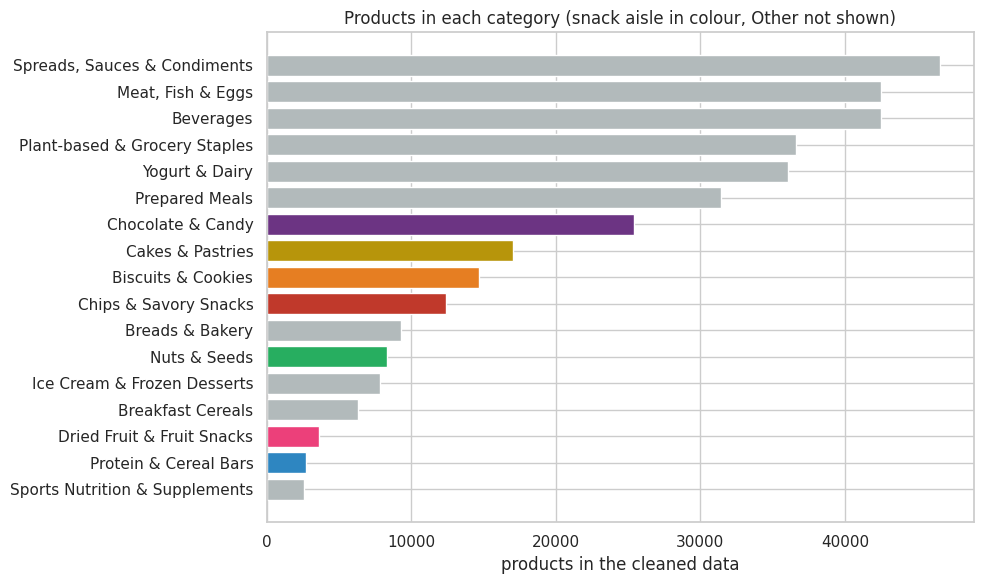

,products,from_tags,from_name,share_%,snack_aisle
category,,,,,
Other / Uncategorised,87177,0,0,20.1,False
"Spreads, Sauces & Condiments",46599,42558,4041,10.8,False
"Meat, Fish & Eggs",42524,37013,5453,9.8,False
Beverages,42480,38184,4296,9.8,False
Plant-based & Grocery Staples,36651,29333,7318,8.5,False
Yogurt & Dairy,36072,32481,3591,8.3,False
Prepared Meals,31455,27669,3128,7.3,False
Chocolate & Candy,25399,21681,3718,5.9,True
Cakes & Pastries,17034,15177,1857,3.9,True


In [33]:
results = [assign_category(tags, name, brands, group, protein)
           for tags, name, brands, group, protein
           in zip(clean["categories_tags"], clean["product_name"], clean["brands"],
                  clean["pnns_groups_2"], clean["proteins_100g"])]

clean["category"] = [r[0] for r in results]
clean["decided_by"] = [r[1] for r in results]
clean["matched_word"] = [r[2] for r in results]
clean["is_snack"] = clean["category"].isin(SNACK_CATEGORIES)

CATEGORY_COUNTS = (clean.groupby("category")
                   .agg(products=("decided_by", "size"),
                        from_tags=("decided_by", lambda s: int((s == "tag").sum())),
                        from_name=("decided_by", lambda s: int((s == "name").sum())))
                   .sort_values("products", ascending=False))
CATEGORY_COUNTS["share_%"] = (CATEGORY_COUNTS["products"] / ROWS_CLEAN * 100).round(1)
CATEGORY_COUNTS["snack_aisle"] = CATEGORY_COUNTS.index.isin(SNACK_CATEGORIES)
CATEGORY_COUNTS.to_csv(os.path.join(OUTPUT_DIR, "category_counts.csv"))

OTHER_SHARE = (clean["category"] == OTHER).mean() * 100
FROM_TAGS_SHARE = (clean["decided_by"] == "tag").mean() * 100
FROM_NAME_SHARE = (clean["decided_by"] == "name").mean() * 100
SNACK_COUNT = int(clean["is_snack"].sum())
MOVED_TO_SUPPLEMENTS = int((clean["category"] == SUPPLEMENTS).sum())
MOVED_BY_PROTEIN = int((clean["decided_by"] == "protein too high for a sweet").sum())
MOVED_BY_FOOD_GROUP = int((clean["decided_by"] == "food group wins").sum())

print(f"Left in '{OTHER}': {OTHER_SHARE:.1f}% of {ROWS_CLEAN:,} products")
print(f"Decided by tags: {FROM_TAGS_SHARE:.1f}%   by product name: {FROM_NAME_SHARE:.1f}%")
print(f"Snack-aisle products: {SNACK_COUNT:,} ({SNACK_COUNT / ROWS_CLEAN:.1%})")
print(f"Moved to '{SUPPLEMENTS}': {MOVED_TO_SUPPLEMENTS:,} "
      f"(of which {MOVED_BY_PROTEIN:,} by the protein guard)")
print(f"Moved because the recorded food group disagreed: {MOVED_BY_FOOD_GROUP:,}")

to_plot = CATEGORY_COUNTS.drop(OTHER, errors="ignore").sort_values("products")
plt.figure(figsize=(10, 6))
plt.barh(to_plot.index, to_plot["products"],
         color=[SNACK_COLOURS.get(name, "#b2babb") for name in to_plot.index])
plt.title("Products in each category (snack aisle in colour, Other not shown)")
plt.xlabel("products in the cleaned data")
plt.tight_layout()
plt.show()
CATEGORY_COUNTS

### Checking the category labels

Rules can be wrong, so the labels are checked three ways.

1. **What is left over.** The most common tags among the *Other* products show what the rules do not reach.
2. **A second opinion.** Open Food Facts records its own food group for many products. Comparing the two is a
   useful sanity check, but not an independent one, because that same field settles a few category clashes.
3. **Reading products by hand.** Ten products from each category were read and marked correct or not. This
   gives a measured accuracy instead of an assumed one.

In [34]:
other_products = clean[clean["category"] == OTHER]
tag_counts = Counter(tag for tags in other_products["categories_tags"].dropna()
                     for tag in english_tags(tags))

print(f"{len(other_products):,} products are in '{OTHER}'. "
      f"{other_products['categories_tags'].isna().mean():.0%} of them carry no tags at all.")
print("\nThe most common tags among them:")
for tag, count in tag_counts.most_common(15):
    print(f"  {count:>8,}  {tag}")

print("\nA few of these products:")
other_products.sample(min(10, len(other_products)), random_state=RANDOM_SEED)[
    ["product_name", "categories_tags"]]

87,177 products are in 'Other / Uncategorised'. 68% of them carry no tags at all.

The most common tags among them:
     5,560  undefined
     1,552  salted-snacks
     1,149  frozen-foods
     1,120  pickles
     1,086  plant-based-pickles
     1,054  olive-tree-products
     1,049  olives
       893  desserts
       870  cooking-helpers
       835  vegetables-based-foods
       752  meat-alternatives
       606  baking-decorations
       596  green-olives
       556  gingerbreads
       523  fats

A few of these products:


,product_name,categories_tags
130501,Christmas Pudding,"en:desserts,en:puddings,en:christmas-puddings"
306665,Croquandises à la figue,None
344742,Pomme et poire bio sans sucre,None
214008,Cochonailles du haut bois,None
312406,"Petits Pots Pomme deTerre, Petits Pois & Jambon de France","en:baby-foods,en:from-8-months"
129315,Noix de coco morceaux,None
172405,Stuffed Green Olives,"en:plant-based-foods-and-beverages,en:plant-based-foods,en:pickles,en:olive-tree-products,en:plant-based-p..."
497156,Boller i karry,None
386003,Sensation fondante mousse citron,"en:desserts,en:sweet-mousses,en:fruit-mousses"
230262,Crevettes entières cuites sauvages,None


In [35]:
# The food group we would expect each category to have, as lower-case fragments.
EXPECTED_FOOD_GROUP = {
    "Ice Cream & Frozen Desserts": ["ice cream"],
    "Biscuits & Cookies": ["biscuit"],
    "Cakes & Pastries": ["cake", "pastr"],
    "Breakfast Cereals": ["breakfast cereal"],
    "Nuts & Seeds": ["nut"],
    "Chips & Savory Snacks": ["appetizer", "salty and fatty"],
    "Beverages": ["beverage", "juice", "nectar", "water", "tea", "milk substitute"],
    "Prepared Meals": ["one-dish", "pizza", "sandwich", "soup"],
    "Breads & Bakery": ["bread"],
    "Yogurt & Dairy": ["cheese", "milk and yogurt", "dairy dessert"],
    "Chocolate & Candy": ["chocolate", "sweets"],
    "Dried Fruit & Fruit Snacks": ["dried fruit"],
    "Meat, Fish & Eggs": ["meat", "fish", "egg", "offal"],
    "Plant-based & Grocery Staples": ["cereals", "legume", "potato", "vegetable", "fruits", "fats"],
}

food_group = clean["pnns_groups_2"].astype("string").str.strip()
has_group = food_group.notna() & (food_group.str.lower() != "unknown")

FOOD_GROUP_AGREEMENT = None
if has_group.sum() == 0:
    print("No food groups are filled in for this slice, so this check is skipped.")
else:
    rows = []
    for category in CATEGORY_NAMES:
        in_category = (clean["category"] == category) & has_group
        expected = EXPECTED_FOOD_GROUP.get(category)
        if expected and in_category.sum():
            matches = food_group[in_category].str.lower().apply(
                lambda value: any(word in value for word in expected))
            agreement = round(matches.mean() * 100, 1)
        else:
            agreement = np.nan
        common = food_group[in_category].value_counts().head(3)
        rows.append({"category": category,
                     "products_with_a_food_group": int(in_category.sum()),
                     "agreement_%": agreement,
                     "most_common_food_groups": "; ".join(f"{k} ({v:,})" for k, v in common.items())})

    FOOD_GROUP_CHECK = pd.DataFrame(rows).set_index("category")
    FOOD_GROUP_CHECK.to_csv(os.path.join(OUTPUT_DIR, "category_food_group_check.csv"))
    scored = FOOD_GROUP_CHECK["agreement_%"].notna()
    if scored.any():
        FOOD_GROUP_AGREEMENT = float(np.average(
            FOOD_GROUP_CHECK.loc[scored, "agreement_%"],
            weights=FOOD_GROUP_CHECK.loc[scored, "products_with_a_food_group"]))
        print(f"The recorded food group agrees with our category for "
              f"{FOOD_GROUP_AGREEMENT:.1f}% of products that have one.")
        lowest = FOOD_GROUP_CHECK["agreement_%"].dropna().nsmallest(3)
        print("Lowest agreement:", ", ".join(f"{k} {v:.0f}%" for k, v in lowest.items()))
    display(FOOD_GROUP_CHECK)

The recorded food group agrees with our category for 91.9% of products that have one.
Lowest agreement: Breakfast Cereals 74%, Chips & Savory Snacks 76%, Prepared Meals 81%


,products_with_a_food_group,agreement_%,most_common_food_groups
category,,,
Protein & Cereal Bars,1251,NaN,"Biscuits and cakes (1,220); Cereals (6); Sweets (5)"
Ice Cream & Frozen Desserts,3567,93.2,"Ice cream (3,326); Biscuits and cakes (117); Milk and yogurt (61)"
Biscuits & Cookies,13083,96.8,"Biscuits and cakes (12,664); Cereals (169); Sweets (59)"
Cakes & Pastries,14575,89.4,"Biscuits and cakes (10,921); Pastries (2,110); Cereals (967)"
Breakfast Cereals,5578,73.5,"Breakfast cereals (4,100); Cereals (1,364); Baby foods (70)"
"Spreads, Sauces & Condiments",37781,NaN,"Dressings and sauces (19,950); Sweets (9,615); Fats (2,340)"
Nuts & Seeds,3864,82.7,"Nuts (3,195); Sweets (259); Cereals (157)"
Chips & Savory Snacks,7623,75.8,"Appetizers (5,663); Potatoes (725); Biscuits and cakes (644)"
Beverages,35162,93.7,"Sweetened beverages (11,599); Fruit juices (4,521); Artificially sweetened beverages (4,450)"


In [36]:
PER_CATEGORY = 10
AUDIT_FILE = os.path.join(OUTPUT_DIR, "category_audit_sample.csv")


def short_tag_list(tags, how_many=6):
    kept = english_tags(tags)
    return ", ".join(kept[-how_many:])


chosen = (clean.sample(frac=1, random_state=RANDOM_SEED)       # shuffle, then take the first few per category
          .groupby("category", sort=False).head(PER_CATEGORY)
          .sort_values("category"))

AUDIT_SAMPLE = pd.DataFrame({
    "audit_id": range(1, len(chosen) + 1),
    "code": as_text(chosen["code"]).to_numpy(),
    "product_name": chosen["product_name"].to_numpy(),
    "category": chosen["category"].to_numpy(),
    "decided_by": chosen["decided_by"].to_numpy(),
    "matched_word": as_text(chosen["matched_word"]).to_numpy(),
    "tags": [short_tag_list(t) for t in chosen["categories_tags"]],
    "food_group": chosen["pnns_groups_2"].to_numpy(),
    "is_correct": "",            # Y or N
    "correct_category": "",      # the right category when the answer is N
    "notes": "",
})
AUDIT_SAMPLE.to_csv(AUDIT_FILE, index=False)

AUDIT_ACCURACY = None
AUDIT_COUNT = 0
AUDIT_MAIN_ERRORS = None

print("Category label review:")
review = load_review("category_audit", "is_correct", {"y", "n"}, AUDIT_SAMPLE,
                     ["audit_id", "code", "product_name", "category"])

if review is None:
    print(f"  not loaded. The sample of {len(AUDIT_SAMPLE)} products is saved at {AUDIT_FILE}.")
else:
    review["correct"] = review["is_correct"].eq("y")
    # Accuracy covers the products that were given a category. 'Other' answers a
    # different question (could it have been placed at all?) and is reported apart.
    classified = review[review["category"] != OTHER]
    AUDIT_COUNT = len(classified)
    AUDIT_ACCURACY = classified["correct"].mean() * 100

    by_category = review.groupby("category")["correct"].agg(checked="size", correct="sum")
    by_category["accuracy_%"] = (by_category["correct"] / by_category["checked"] * 100).round(0)
    by_category.to_csv(os.path.join(OUTPUT_DIR, "category_audit_results.csv"))

    by_method = review.groupby("decided_by")["correct"].agg(checked="size", correct="sum")
    by_method["accuracy_%"] = (by_method["correct"] / by_method["checked"] * 100).round(0)

    mistakes = review[~review["correct"]]
    confusions = (mistakes.groupby(["category", "correct_category"]).size()
                  .sort_values(ascending=False))
    AUDIT_MAIN_ERRORS = "; ".join(
        (f"{given} marked wrong ({n})" if right == ""
         else f"{given} that should have been {right} ({n})")
        for (given, right), n in confusions.head(3).items())

    other_rows = review[review["category"] == OTHER]
    print(f"  {AUDIT_ACCURACY:.1f}% of {AUDIT_COUNT} labelled products were correct. "
          f"Ten products per category were read, so this is not weighted by how common each category is.")
    if len(other_rows):
        placeable = int((~other_rows["correct"]).sum())
        print(f"  Of {len(other_rows)} products left in '{OTHER}', {placeable} could have been placed "
              f"in a category. They carry no usable tags.")
    print("  By method:", ", ".join(f"{m} {r['accuracy_%']:.0f}% (n={int(r['checked'])})"
                                    for m, r in by_method.iterrows()))
    if AUDIT_MAIN_ERRORS:
        print("  Most common mistakes:", AUDIT_MAIN_ERRORS)
    display(by_category.sort_values("accuracy_%"))

Category label review:
  not loaded. The sample of 180 products is saved at outputs/category_audit_sample.csv.


## 4 · Story 3 — Sugar against protein

A product counts as **low sugar and high protein** when it has:

- **5 g of sugar or less per 100 g.** This is the European limit for calling a solid food "low in sugars"
  (Regulation (EC) No 1924/2006), and the "low" band on United Kingdom front-of-pack labels. A product at
  this level could carry the claim on its wrapper.
- **15 g of protein or more per 100 g.** There is no legal figure per 100 g. The European "high protein"
  claim is based on energy instead: at least 20% of the energy must come from protein. 15 g is used here as a
  practical bar that ordinary sweets do not reach but nuts and protein bars do.

Because 15 g is a judgement, every figure below is repeated under seven other settings, including the
European energy-based rule.

All percentages come from the full cleaned table. The scatter plot draws a random sample, so that the points
stay readable, and the plot title says so. Every statement about scarcity names its category and the number
of products it is out of.

In [37]:
SUGAR_LIMIT = 5.0      # g per 100 g, the European "low in sugars" claim
PROTEIN_LIMIT = 15.0   # g per 100 g, a practical bar, tested again below


def meets_both(frame, sugar_limit=SUGAR_LIMIT, protein_limit=PROTEIN_LIMIT):
    return (frame["sugars_100g"] <= sugar_limit) & (frame["proteins_100g"] >= protein_limit)


clean["qualifies"] = meets_both(clean)

QUALIFY_ALL = clean["qualifies"].mean() * 100
QUALIFY_SNACKS = clean.loc[clean["is_snack"], "qualifies"].mean() * 100

BY_CATEGORY = clean.groupby("category")["qualifies"].agg(products="size", qualifying="sum")
BY_CATEGORY["share_%"] = (BY_CATEGORY["qualifying"] / BY_CATEGORY["products"] * 100).round(1)
BY_CATEGORY["snack_aisle"] = BY_CATEGORY.index.isin(SNACK_CATEGORIES)
BY_CATEGORY = BY_CATEGORY.sort_values("share_%")
BY_CATEGORY.to_csv(os.path.join(OUTPUT_DIR, "qualifying_share_by_category.csv"))

biggest_sources = BY_CATEGORY.sort_values("qualifying", ascending=False).head(3).index.tolist()
scarcest = BY_CATEGORY[BY_CATEGORY["snack_aisle"]].head(3)
SCARCEST_TEXT = "; ".join(f"{name}: {int(row.qualifying):,} of {int(row.products):,} ({row['share_%']:.1f}%)"
                          for name, row in scarcest.iterrows())

print(f"All cleaned products: {int(clean['qualifies'].sum()):,} of {ROWS_CLEAN:,} "
      f"meet both limits ({QUALIFY_ALL:.1f}%).")
print(f"Snack aisle only:     {int(clean.loc[clean['is_snack'], 'qualifies'].sum()):,} "
      f"of {SNACK_COUNT:,} ({QUALIFY_SNACKS:.1f}%).")
print(f"Most of the qualifying products sit in: {'; '.join(biggest_sources)}.")
print(f"Scarcest snack categories: {SCARCEST_TEXT}")
BY_CATEGORY

All cleaned products: 65,646 of 433,181 meet both limits (15.2%).
Snack aisle only:     4,323 of 84,200 (5.1%).
Most of the qualifying products sit in: Meat, Fish & Eggs; Yogurt & Dairy; Other / Uncategorised.
Scarcest snack categories: Chocolate & Candy: 57 of 25,399 (0.2%); Cakes & Pastries: 110 of 17,034 (0.6%); Biscuits & Cookies: 81 of 14,708 (0.6%)


,products,qualifying,share_%,snack_aisle
category,,,,
Ice Cream & Frozen Desserts,7853,2,0.0,False
Chocolate & Candy,25399,57,0.2,True
Cakes & Pastries,17034,110,0.6,True
Biscuits & Cookies,14708,81,0.6,True
Beverages,42480,287,0.7,False
Dried Fruit & Fruit Snacks,3628,30,0.8,True
Breakfast Cereals,6321,98,1.6,False
Breads & Bakery,9274,212,2.3,False
"Spreads, Sauces & Condiments",46599,1626,3.5,False


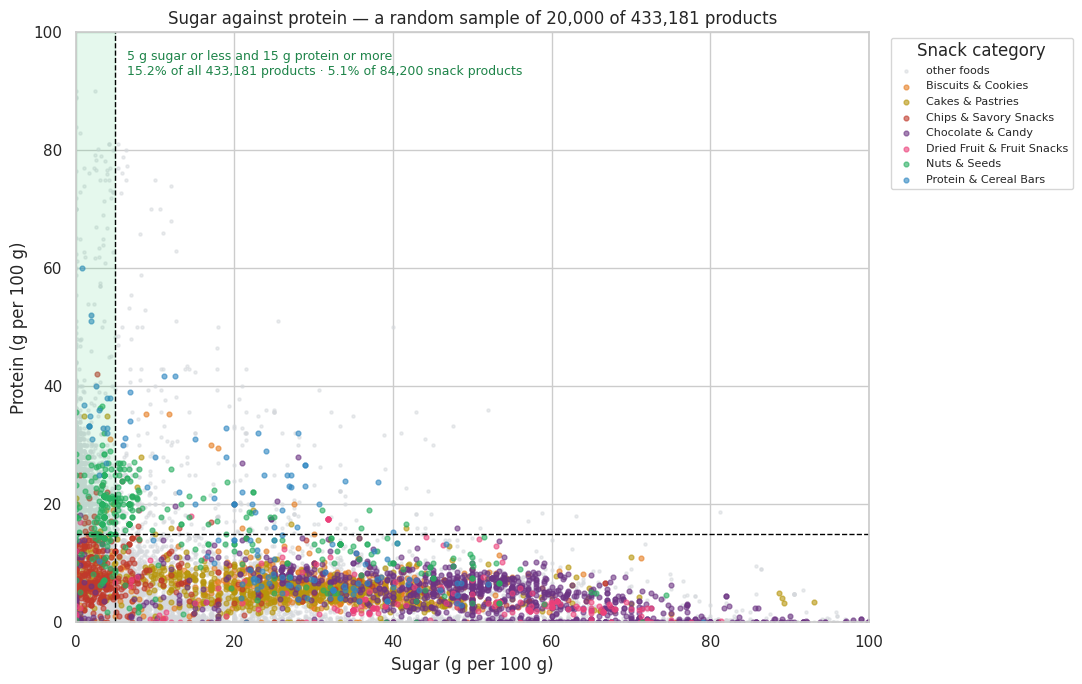

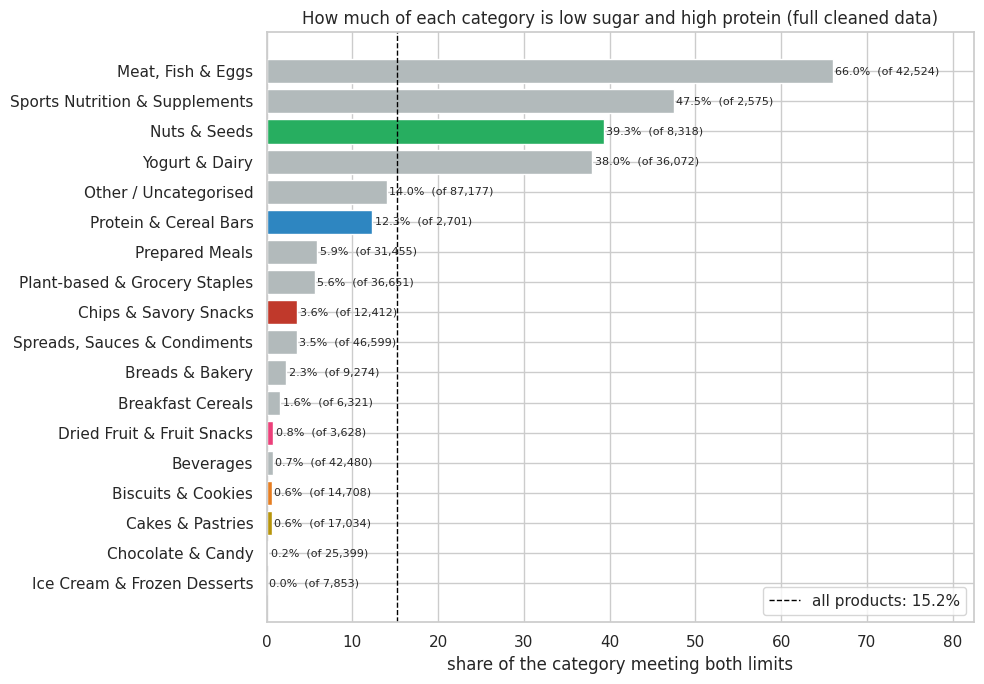

In [38]:
POINTS_TO_PLOT = 20_000
sample_to_plot = clean.sample(min(POINTS_TO_PLOT, ROWS_CLEAN), random_state=RANDOM_SEED)
snack_points = sample_to_plot[sample_to_plot["is_snack"]]
other_points = sample_to_plot[~sample_to_plot["is_snack"]]

figure, axis = plt.subplots(figsize=(11, 7))
axis.scatter(other_points["sugars_100g"], other_points["proteins_100g"],
             s=5, c="#d5d8dc", alpha=0.5, label="other foods")
for name, group in snack_points.groupby("category"):
    axis.scatter(group["sugars_100g"], group["proteins_100g"], s=12, alpha=0.6,
                 c=SNACK_COLOURS.get(name, "#7f8c8d"), label=name)
axis.add_patch(plt.Rectangle((0, PROTEIN_LIMIT), SUGAR_LIMIT, 100 - PROTEIN_LIMIT,
                             color="#2ecc71", alpha=0.12))
axis.axvline(SUGAR_LIMIT, color="black", ls="--", lw=1)
axis.axhline(PROTEIN_LIMIT, color="black", ls="--", lw=1)
axis.text(SUGAR_LIMIT + 1.5, 97,
          f"{SUGAR_LIMIT:g} g sugar or less and {PROTEIN_LIMIT:g} g protein or more\n"
          f"{QUALIFY_ALL:.1f}% of all {ROWS_CLEAN:,} products · "
          f"{QUALIFY_SNACKS:.1f}% of {SNACK_COUNT:,} snack products",
          va="top", fontsize=9, color="#1e8449")
axis.set_xlim(0, 100)
axis.set_ylim(0, 100)
axis.set_title(f"Sugar against protein — a random sample of {len(sample_to_plot):,} of {ROWS_CLEAN:,} products")
axis.set_xlabel("Sugar (g per 100 g)")
axis.set_ylabel("Protein (g per 100 g)")
axis.legend(title="Snack category", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

figure, axis = plt.subplots(figsize=(10, 7))
axis.barh(BY_CATEGORY.index, BY_CATEGORY["share_%"],
          color=[SNACK_COLOURS.get(name, "#b2babb") for name in BY_CATEGORY.index])
for position, (share, total) in enumerate(zip(BY_CATEGORY["share_%"], BY_CATEGORY["products"])):
    axis.text(share + 0.3, position, f"{share:.1f}%  (of {total:,})", va="center", fontsize=8)
axis.axvline(QUALIFY_ALL, color="black", ls="--", lw=1, label=f"all products: {QUALIFY_ALL:.1f}%")
axis.set_xlim(0, max(BY_CATEGORY["share_%"].max() * 1.25, 5))
axis.set_xlabel("share of the category meeting both limits")
axis.set_title("How much of each category is low sugar and high protein (full cleaned data)")
axis.legend()
plt.tight_layout()
plt.show()

### Does the answer change if the limits change?

Seven settings are tried. Six move one limit at a time. The seventh uses the European "high protein" rule,
where at least 20% of a product's energy must come from protein. For that one, energy is the reported value,
or an estimate from the nutrients when it is missing; products with neither are left out and their number is
reported.

Setting 7 can be worked out for 423,744 of 433,181 products.
Across the seven settings: all products 9.8% to 23.2%, snack aisle 1.6% to 8.7%.

Scarcest snack category under each setting:
  1 base: sugar 5, protein 15                              Chocolate & Candy (0.2%)
  2 protein 10                                             Chocolate & Candy (0.6%)
  3 protein 12                                             Chocolate & Candy (0.5%)
  4 protein 20                                             Chocolate & Candy (0.2%)
  5 sugar 2.5                                              Chocolate & Candy (0.1%)
  6 sugar 10                                               Chocolate & Candy (0.3%)
  7 European claims: sugar 5, 20% of energy from protein   Biscuits & Cookies (0.3%)


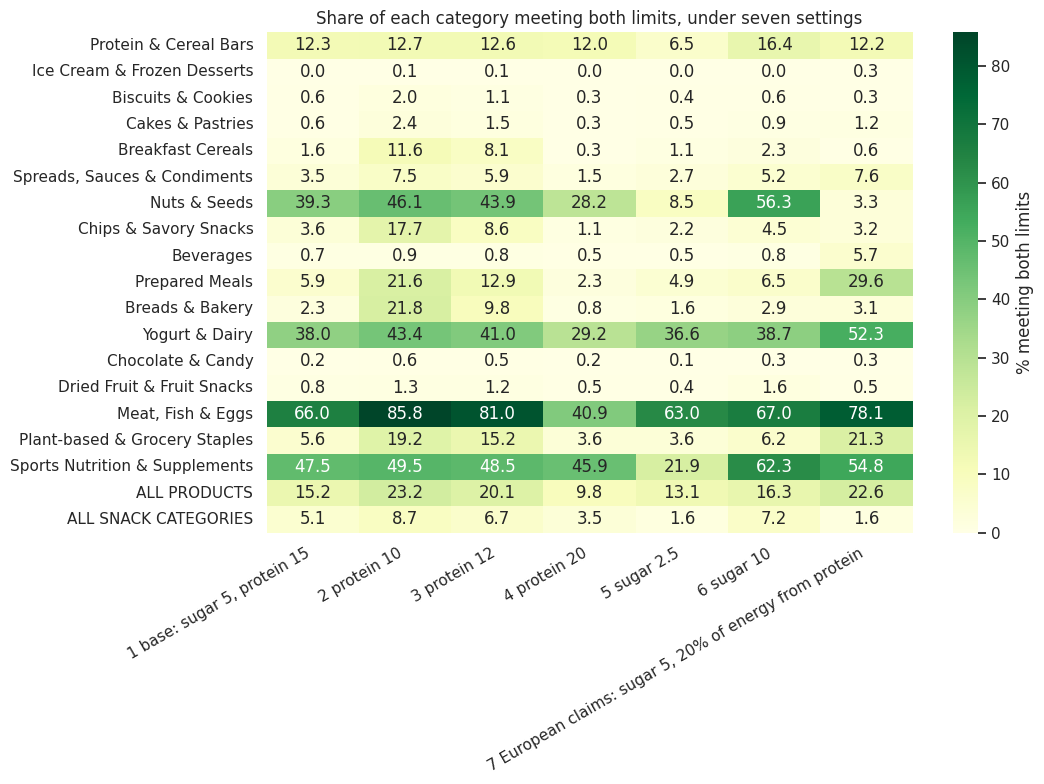

In [39]:
estimated_energy = (4 * clean["proteins_100g"] + 4 * clean["carbohydrates_100g"]
                    + 9 * clean["fat_100g"])
energy = clean["energy-kcal_100g"].where(clean["energy-kcal_100g"] > 0, estimated_energy)
energy = energy.where(energy > 0)
protein_share_of_energy = 4 * clean["proteins_100g"] / energy

SETTINGS = {
    "1 base: sugar 5, protein 15": meets_both(clean).astype(float),
    "2 protein 10": meets_both(clean, protein_limit=10).astype(float),
    "3 protein 12": meets_both(clean, protein_limit=12).astype(float),
    "4 protein 20": meets_both(clean, protein_limit=20).astype(float),
    "5 sugar 2.5": meets_both(clean, sugar_limit=2.5).astype(float),
    "6 sugar 10": meets_both(clean, sugar_limit=10).astype(float),
    "7 European claims: sugar 5, 20% of energy from protein":
        ((clean["sugars_100g"] <= SUGAR_LIMIT) & (protein_share_of_energy >= 0.20))
        .astype(float).where(energy.notna()),
}

settings_frame = pd.DataFrame(SETTINGS)
per_category = settings_frame.groupby(clean["category"]).mean() * 100
SETTINGS_TABLE = pd.concat([
    per_category.loc[[c for c in CATEGORY_NAMES if c in per_category.index]],
    (settings_frame.mean() * 100).to_frame("ALL PRODUCTS").T,
    (settings_frame[clean["is_snack"]].mean() * 100).to_frame("ALL SNACK CATEGORIES").T,
]).round(1)
SETTINGS_TABLE.to_csv(os.path.join(OUTPUT_DIR, "threshold_sensitivity.csv"))

snack_row = SETTINGS_TABLE.loc["ALL SNACK CATEGORIES"]
all_row = SETTINGS_TABLE.loc["ALL PRODUCTS"]
SNACK_RANGE = (snack_row.min(), snack_row.max())

print(f"Setting 7 can be worked out for {int(energy.notna().sum()):,} of {ROWS_CLEAN:,} products.")
print(f"Across the seven settings: all products {all_row.min():.1f}% to {all_row.max():.1f}%, "
      f"snack aisle {SNACK_RANGE[0]:.1f}% to {SNACK_RANGE[1]:.1f}%.")
snack_rows = [c for c in CATEGORY_NAMES if c in SNACK_CATEGORIES and c in SETTINGS_TABLE.index]
print("\nScarcest snack category under each setting:")
for setting, category in SETTINGS_TABLE.loc[snack_rows].idxmin().items():
    print(f"  {setting:<56} {category} ({SETTINGS_TABLE.loc[category, setting]:.1f}%)")

plt.figure(figsize=(11, 8))
sns.heatmap(SETTINGS_TABLE, annot=True, fmt=".1f", cmap="YlGn",
            cbar_kws={"label": "% meeting both limits"})
plt.xticks(rotation=30, ha="right")
plt.title("Share of each category meeting both limits, under seven settings")
plt.tight_layout()
plt.show()

## 5 · Candidate's Choice — scoring the gap in each category

Story 3 shows where the gap is. A product team also needs to know **which gap to work on first**, so each
snack category gets a score.

**The score.** For a category *c*:

$$\text{white space}(c) = \frac{N_c}{\max_k N_k} \times (1 - q_c)$$

$N_c$ is how many products the category has, and $q_c$ is the share of them that meet both limits. The score
rises with $N_c(1 - q_c)$, which is simply **how many listings in that category have no low-sugar,
high-protein version**, rescaled so the largest category scores 1.

**Why these two parts.** The size of a category shows it is an established shelf that many brands already
supply, so a healthier product would have somewhere to sit. The qualifying share shows how crowded the
healthy corner already is. A large category with a tiny qualifying share is a large, visible gap in the
catalog.

**What the score is not.** It contains no sales, no prices and nothing about what shoppers prefer. It ranks
gaps in a catalog; it does not measure demand.

**It favours large categories on purpose.** Because the score counts non-qualifying listings, bigger
categories score higher by design. So a category that stays first across the settings below is robust to
those settings, not independent of its own size. The last setting removes size altogether and is reported
separately for that reason.

score = (products / 25,399) x (1 - qualifying share)
Largest catalog white space: Chocolate & Candy


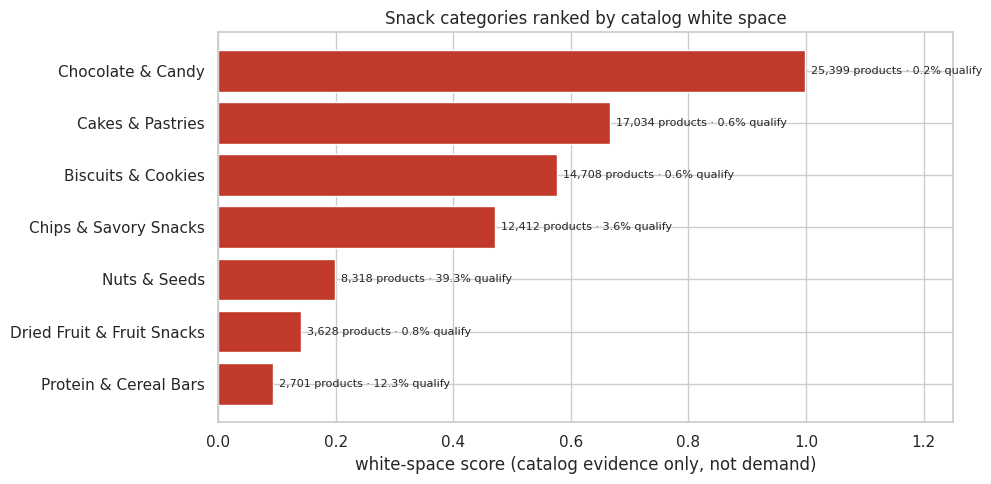

,products,qualifying,qualifying_share,white_space_score,rank
category,,,,,
Chocolate & Candy,25399,57.0,0.002244,0.9978,1
Cakes & Pastries,17034,110.0,0.006458,0.6663,2
Biscuits & Cookies,14708,81.0,0.005507,0.5759,3
Chips & Savory Snacks,12412,443.0,0.035691,0.4712,4
Nuts & Seeds,8318,3269.0,0.393003,0.1988,5
Dried Fruit & Fruit Snacks,3628,30.0,0.008269,0.1417,6
Protein & Cereal Bars,2701,333.0,0.123288,0.0932,7


In [40]:
def white_space_table(categories, qualifies, weighting="size"):
    """Rank the snack categories by how much catalog white space they have.

    weighting:
      'size'       the score in the formula above
      'log size'   dampens the effect of a large category
      'share only' ignores size completely
    """
    frame = pd.DataFrame({"category": np.asarray(categories),
                          "qualifies": np.asarray(qualifies, dtype=float)})
    frame = frame[frame["category"].isin(SNACK_CATEGORIES)]

    table = frame.groupby("category")["qualifies"].agg(products="count", qualifying="sum")
    table["qualifying_share"] = table["qualifying"] / table["products"]

    if weighting == "size":
        size_part = table["products"] / table["products"].max()
    elif weighting == "log size":
        size_part = np.log1p(table["products"]) / np.log1p(table["products"].max())
    else:
        size_part = 1.0

    table["white_space_score"] = (size_part * (1 - table["qualifying_share"])).round(4)
    table = table.sort_values("white_space_score", ascending=False)
    table["rank"] = range(1, len(table) + 1)
    return table


WHITE_SPACE = white_space_table(clean["category"], clean["qualifies"])
WHITE_SPACE.to_csv(os.path.join(OUTPUT_DIR, "white_space_score.csv"))
TOP_CATEGORY = WHITE_SPACE.index[0]

print(f"score = (products / {int(WHITE_SPACE['products'].max()):,}) x (1 - qualifying share)")
print(f"Largest catalog white space: {TOP_CATEGORY}")

plt.figure(figsize=(10, 5))
plt.barh(WHITE_SPACE.index[::-1], WHITE_SPACE["white_space_score"][::-1], color="#c0392b")
for position, (name, row) in enumerate(WHITE_SPACE[::-1].iterrows()):
    plt.text(row["white_space_score"] + 0.01, position,
             f"{int(row['products']):,} products · {row['qualifying_share']:.1%} qualify",
             va="center", fontsize=8)
plt.xlim(0, 1.25)
plt.xlabel("white-space score (catalog evidence only, not demand)")
plt.title("Snack categories ranked by catalog white space")
plt.tight_layout()
plt.show()
WHITE_SPACE

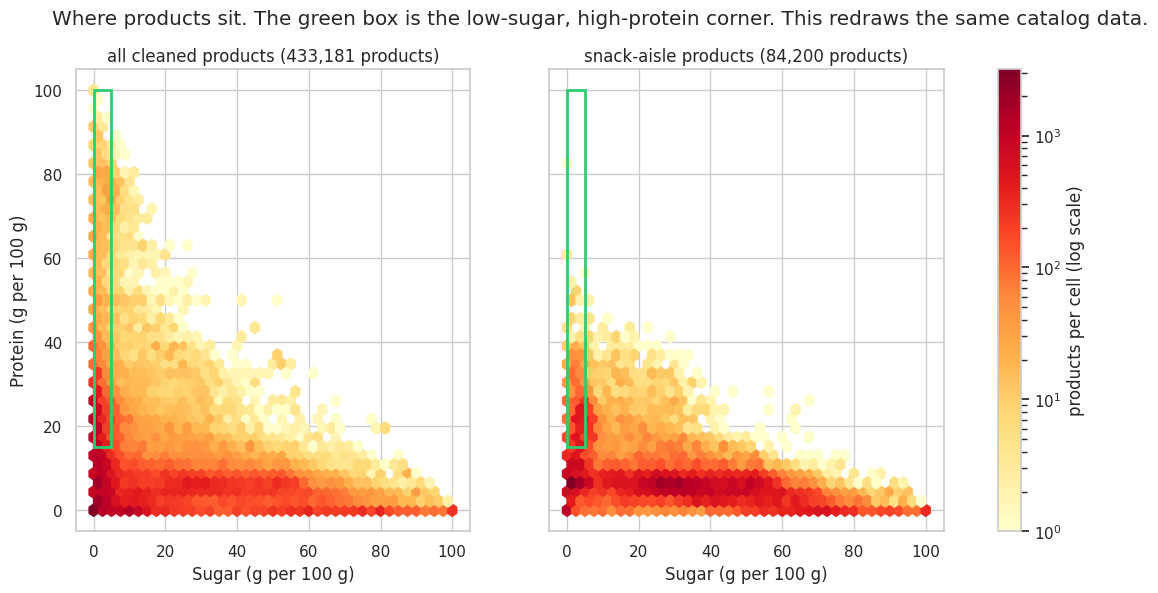

In [41]:
figure, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for axis, (label, frame) in zip(axes, [("all cleaned products", clean),
                                       ("snack-aisle products", clean[clean["is_snack"]])]):
    picture = axis.hexbin(frame["sugars_100g"], frame["proteins_100g"], gridsize=40,
                          extent=(0, 100, 0, 100), bins="log", cmap="YlOrRd", mincnt=1)
    axis.add_patch(plt.Rectangle((0, PROTEIN_LIMIT), SUGAR_LIMIT, 100 - PROTEIN_LIMIT,
                                 fill=False, ec="#2ecc71", lw=2))
    axis.set_title(f"{label} ({len(frame):,} products)")
    axis.set_xlabel("Sugar (g per 100 g)")
axes[0].set_ylabel("Protein (g per 100 g)")
figure.colorbar(picture, ax=axes, label="products per cell (log scale)")
figure.suptitle("Where products sit. The green box is the low-sugar, high-protein corner. "
                "This redraws the same catalog data.")
plt.show()

### Does the top category change under other rules?

The ranking is worked out again under each of the seven limit settings, with the categories decided from tags
and the form rules only, and with two other weightings.

In [42]:
categories_without_name_rule = [
    assign_category(tags, name, brands, group, protein, use_name=False)[0]
    for tags, name, brands, group, protein
    in zip(clean["categories_tags"], clean["product_name"], clean["brands"],
           clean["pnns_groups_2"], clean["proteins_100g"])]

RANKINGS = {name: white_space_table(clean["category"], values) for name, values in SETTINGS.items()}
RANKINGS["8 categories without the product-name rule"] = white_space_table(
    categories_without_name_rule, clean["qualifies"])
RANKINGS["9 log size weighting"] = white_space_table(clean["category"], clean["qualifies"], "log size")
SHARE_ONLY = "10 qualifying share only, size ignored"
RANKINGS[SHARE_ONLY] = white_space_table(clean["category"], clean["qualifies"], "share only")

rows = []
for setting, table in RANKINGS.items():
    rows.append({"setting": setting,
                 "1st": table.index[0],
                 "2nd": table.index[1] if len(table) > 1 else "",
                 "3rd": table.index[2] if len(table) > 2 else "",
                 f"rank of {TOP_CATEGORY}": int(table.loc[TOP_CATEGORY, "rank"])
                 if TOP_CATEGORY in table.index else None})
RANKING_CHECK = pd.DataFrame(rows).set_index("setting")
RANKING_CHECK.to_csv(os.path.join(OUTPUT_DIR, "ranking_sensitivity.csv"))

size_based = RANKING_CHECK.drop(index=SHARE_ONLY)
FIRST_IN_SIZE_BASED = int((size_based["1st"] == TOP_CATEGORY).sum())
SIZE_BASED_COUNT = len(size_based)
RANK_WITHOUT_SIZE = int(RANKING_CHECK.loc[SHARE_ONLY, f"rank of {TOP_CATEGORY}"])
LEADER_WITHOUT_SIZE = RANKING_CHECK.loc[SHARE_ONLY, "1st"]

WEIGHTING_NOTE = (f"first in {FIRST_IN_SIZE_BASED} of {SIZE_BASED_COUNT} settings that keep the size part "
                  f"(these vary the limits and the category rules, and larger categories score higher by "
                  f"design); with size removed it ranks {RANK_WITHOUT_SIZE}, behind {LEADER_WITHOUT_SIZE}")

print(f"{TOP_CATEGORY} is {WEIGHTING_NOTE}.")
RANKING_CHECK

Chocolate & Candy is first in 9 of 9 settings that keep the size part (these vary the limits and the category rules, and larger categories score higher by design); with size removed it ranks 1, behind Chocolate & Candy.


,1st,2nd,3rd,rank of Chocolate & Candy
setting,,,,
"1 base: sugar 5, protein 15",Chocolate & Candy,Cakes & Pastries,Biscuits & Cookies,1
2 protein 10,Chocolate & Candy,Cakes & Pastries,Biscuits & Cookies,1
3 protein 12,Chocolate & Candy,Cakes & Pastries,Biscuits & Cookies,1
4 protein 20,Chocolate & Candy,Cakes & Pastries,Biscuits & Cookies,1
5 sugar 2.5,Chocolate & Candy,Cakes & Pastries,Biscuits & Cookies,1
6 sugar 10,Chocolate & Candy,Cakes & Pastries,Biscuits & Cookies,1
"7 European claims: sugar 5, 20% of energy from protein",Chocolate & Candy,Cakes & Pastries,Biscuits & Cookies,1
8 categories without the product-name rule,Chocolate & Candy,Cakes & Pastries,Biscuits & Cookies,1
9 log size weighting,Chocolate & Candy,Cakes & Pastries,Biscuits & Cookies,1


## 6 · Story 4 — The recommendation

The category is the one that scores highest above. It is the strongest **catalog white-space candidate**, not
a proven market.

**Checking the product format first.** A qualifying product only tells us something about a workable recipe
if it really is the kind of product the category is named after. Among products labelled chocolate or candy
there are protein bars, powders, and a few items that are not sweets at all. Each qualifying product in the
category was therefore read and marked as one of four kinds:

| Mark | Meaning |
|---|---|
| c | the category's own kind of product |
| b | a bar or a bite |
| s | a powder or a supplement |
| o | something else, or wrongly labelled |

The protein target is the middle value of the products marked **c**. Until that reading is loaded, no product
is assumed to be of any kind, and the target stays at the 15 g screening level.

In [43]:
MIN_PRODUCTS_FOR_TARGET = 10
FORMAT_FILE = os.path.join(OUTPUT_DIR, "format_review.csv")
FORMAT_MEANING = {"c": "the category's own kind", "b": "bar or bite",
                  "s": "powder or supplement", "o": "something else"}

in_category = clean[clean["category"] == TOP_CATEGORY]
qualifying_in_category = in_category[in_category["qualifies"]]
CATEGORY_MEDIAN_SUGAR = in_category["sugars_100g"].median()
CATEGORY_MEDIAN_PROTEIN = in_category["proteins_100g"].median()
QUALIFYING_SHARE_TEXT = len(qualifying_in_category) / len(in_category) * 100

BAR_IN_NAME = re.compile(r"\b(?:bars?|bites?|barres?|barritas?|riegel)\b")

FORMAT_REVIEW = pd.DataFrame({
    "code": as_text(qualifying_in_category["code"]).to_numpy(),
    "product_name": qualifying_in_category["product_name"].to_numpy(),
    "brands": qualifying_in_category["brands"].to_numpy(),
    "sugars_100g": qualifying_in_category["sugars_100g"].round(1).to_numpy(),
    "proteins_100g": qualifying_in_category["proteins_100g"].round(1).to_numpy(),
    "first_guess": ["b" if BAR_IN_NAME.search(str(name).lower()) else "c"
                    for name in qualifying_in_category["product_name"]],
    "format_confirmed": "",      # c, b, s or o
})
FORMAT_REVIEW.to_csv(FORMAT_FILE, index=False)

print("Product format review:")
format_answers = load_review("format_review", "format_confirmed", set(FORMAT_MEANING),
                             FORMAT_REVIEW, ["code", "product_name"])

if format_answers is None:
    FORMAT_REVIEW["format"] = "not read yet"
    FORMAT_WAS_READ = False
    FORMAT_SOURCE = "not read yet, so no product is counted towards the target"
    print(f"  not loaded. The {len(FORMAT_REVIEW)} qualifying products are listed at {FORMAT_FILE}.")
else:
    answers = (format_answers.drop_duplicates(["code", "product_name"])
               .set_index(["code", "product_name"])["format_confirmed"])
    keys = list(zip(FORMAT_REVIEW["code"], FORMAT_REVIEW["product_name"]))
    FORMAT_REVIEW["format"] = [answers.get(key, "o") for key in keys]
    FORMAT_WAS_READ = True
    FORMAT_SOURCE = f"all {len(FORMAT_REVIEW)} qualifying products were read"
    print(f"  {FORMAT_SOURCE}.")

own_kind = FORMAT_REVIEW[FORMAT_REVIEW["format"] == "c"]
OWN_KIND_COUNT = len(own_kind)
FORMAT_MIX = FORMAT_REVIEW["format"].map(FORMAT_MEANING).fillna("not read yet").value_counts()
FORMAT_REVIEW.to_csv(os.path.join(OUTPUT_DIR, "format_review_result.csv"), index=False)

print(f"\n{TOP_CATEGORY}: {len(in_category):,} products, "
      f"{len(qualifying_in_category):,} meet both limits ({QUALIFYING_SHARE_TEXT:.1f}%).")
print("What those qualifying products actually are:")
print(FORMAT_MIX.to_string())
if OWN_KIND_COUNT:
    print(f"\nMiddle protein value: all qualifying {qualifying_in_category['proteins_100g'].median():.0f} g, "
          f"the category's own kind only {own_kind['proteins_100g'].median():.0f} g "
          f"(from {OWN_KIND_COUNT} products).")
display(FORMAT_REVIEW.assign(format=FORMAT_REVIEW["format"].map(FORMAT_MEANING).fillna("not read yet"))
        .sort_values("proteins_100g", ascending=False)
        [["product_name", "brands", "sugars_100g", "proteins_100g", "format"]].head(25))

Product format review:
  not loaded. The 57 qualifying products are listed at outputs/format_review.csv.

Chocolate & Candy: 25,399 products, 57 meet both limits (0.2%).
What those qualifying products actually are:
format
not read yet    57


,product_name,brands,sugars_100g,proteins_100g,format
16,Protein peanut butter cups,Mr. Beverages Old Time Cocktail Mixes,2.0,40.0,not read yet
40,Body Shaper Low Carb Chocolate Bar,None,2.6,40.0,not read yet
47,Grenade Carb Killa White Chocolate Mocha,None,3.3,37.7,not read yet
1,Chocolate Fudge,Iovate Health Sciences International Inc.,0.0,37.5,not read yet
46,Grenade Carb Killa White Chocolate Bars - 12 x 60G 522 / 8076,Grenade,3.3,37.4,not read yet
56,Diet Bar,Prozis,4.8,37.0,not read yet
42,Imperius,imperius,3.4,36.0,not read yet
53,Diet bar,Prozis,5.0,36.0,not read yet
33,Barre Crisp banane caramel,None,4.9,35.6,not read yet
39,Yippie! High Protein 35% Salted Caramel Flavour,Weider,3.7,35.0,not read yet


Based on the data, the largest catalog white space is in Chocolate & Candy. The suggested product has at
least 15 g of protein and less than 5 g of sugar per 100 g.

Evidence: Chocolate & Candy holds 25,399 products in the cleaned catalog, with a middle value of 50 g
sugar and 5 g protein per 100 g. Only 57 of them (0.2%) have 5 g of sugar or less and 15 g of protein or
more. That makes it the strongest catalog white-space candidate: it is first in 9 of 9 settings that keep
the size part (these vary the limits and the category rules, and larger categories score higher by
design); with size removed it ranks 1, behind Chocolate & Candy. Before scoring, 2,575 powders and
supplements were moved out of the snack aisle. The protein target is the 15 g screening level set before
the analysis, because the product format reading is not read yet, so no product is counted towards the
target. The sugar figure is the European limit for a 'low in sugars' claim; the product target is set
below it, whi

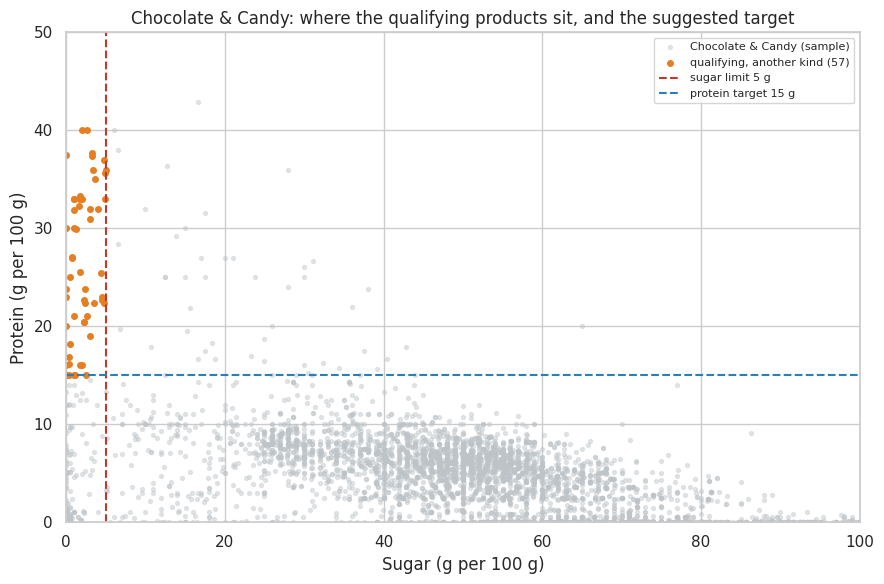

In [44]:
if FORMAT_WAS_READ and OWN_KIND_COUNT >= MIN_PRODUCTS_FOR_TARGET:
    TARGET_PROTEIN = max(PROTEIN_LIMIT, float(np.floor(own_kind["proteins_100g"].median())))
    TARGET_BASIS = (f"the middle protein value of the {OWN_KIND_COUNT} qualifying {TOP_CATEGORY} products "
                    f"that are the category's own kind of product "
                    f"(they run from {own_kind['proteins_100g'].min():.0f} to "
                    f"{own_kind['proteins_100g'].max():.0f} g)")
    TARGET_CAVEAT = ("Most of those products are very dark chocolate, so taste and portion size still need "
                     "testing with shoppers. ")
else:
    TARGET_PROTEIN = PROTEIN_LIMIT
    TARGET_BASIS = (f"the {PROTEIN_LIMIT:g} g screening level set before the analysis, because the product "
                    f"format reading is {FORMAT_SOURCE}")
    TARGET_CAVEAT = ""
TARGET_SUGAR = SUGAR_LIMIT

if AUDIT_ACCURACY is None:
    audit_text = "; the category label reading is not loaded"
else:
    audit_text = (f"; reading ten products from each category found {AUDIT_ACCURACY:.0f}% of "
                  f"{AUDIT_COUNT} labels correct, which is not weighted by how common each category is")

RECOMMENDATION = (
    f"Based on the data, the largest catalog white space is in {TOP_CATEGORY}. The suggested product has at "
    f"least {TARGET_PROTEIN:.0f} g of protein and less than {TARGET_SUGAR:g} g of sugar per 100 g.")

EVIDENCE = (
    f"Evidence: {TOP_CATEGORY} holds {len(in_category):,} products in the cleaned catalog, with a middle value "
    f"of {CATEGORY_MEDIAN_SUGAR:.0f} g sugar and {CATEGORY_MEDIAN_PROTEIN:.0f} g protein per 100 g. Only "
    f"{len(qualifying_in_category):,} of them ({QUALIFYING_SHARE_TEXT:.1f}%) have 5 g of sugar or less and 15 g "
    f"of protein or more. That makes it the strongest catalog white-space candidate: it is {WEIGHTING_NOTE}. "
    f"Before scoring, {MOVED_TO_SUPPLEMENTS:,} powders and supplements were moved out of the snack aisle. The "
    f"protein target is {TARGET_BASIS}. The sugar figure is the European limit for a 'low in sugars' claim; the "
    f"product target is set below it, while the counts above use 5 g or less. {TARGET_CAVEAT}"
    f"Limits of this evidence: product counts describe what is offered in Open Food Facts, not what people buy; "
    f"the entries are written by volunteers; they come from the first {PROVENANCE['rows_read']:,} rows of one "
    f"copy of the export ({source_info.get('last_modified') or 'date unknown'}), which is not a random sample of "
    f"the market; categories are decided by rules{audit_text}. Demand should be tested with sales, search or "
    f"survey data before any product is developed.")

with open(os.path.join(OUTPUT_DIR, "recommendation.txt"), "w", encoding="utf-8") as handle:
    handle.write(RECOMMENDATION + "\n\n" + EVIDENCE + "\n")

print(textwrap.fill(RECOMMENDATION, 105))
print()
print(textwrap.fill(EVIDENCE, 105))

figure, axis = plt.subplots(figsize=(9, 6))
background = in_category.sample(min(5000, len(in_category)), random_state=RANDOM_SEED)
axis.scatter(background["sugars_100g"], background["proteins_100g"], s=8, alpha=0.4,
             c="#bdc3c7", label=f"{TOP_CATEGORY} (sample)")
other_kinds = FORMAT_REVIEW[FORMAT_REVIEW["format"] != "c"]
axis.scatter(other_kinds["sugars_100g"], other_kinds["proteins_100g"], s=16, c="#e67e22",
             label=f"qualifying, another kind ({len(other_kinds)})")
if OWN_KIND_COUNT:
    axis.scatter(own_kind["sugars_100g"], own_kind["proteins_100g"], s=20, c="#1e8449",
                 label=f"qualifying, the category's own kind ({OWN_KIND_COUNT})")
axis.axvline(TARGET_SUGAR, color="#c0392b", ls="--", label=f"sugar limit {TARGET_SUGAR:g} g")
axis.axhline(TARGET_PROTEIN, color="#2980b9", ls="--", label=f"protein target {TARGET_PROTEIN:.0f} g")
axis.set_xlim(0, 100)
axis.set_ylim(0, max(45, in_category["proteins_100g"].max() + 5))
axis.set_title(f"{TOP_CATEGORY}: where the qualifying products sit, and the suggested target")
axis.set_xlabel("Sugar (g per 100 g)")
axis.set_ylabel("Protein (g per 100 g)")
axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7 · Bonus — where the protein comes from

The brief asks for the top three protein sources in the ingredient lists. The answer is given twice for the
recommended category:

1. **The category's own kind of product.** The closer comparison for a recipe.
2. **Every qualifying product in the category.** A wider view that also takes in bars and any format still
   unread.

The two groups overlap, so they are not two separate samples. Each one reports how many products are in it,
how many have a readable ingredient list, and what share of those mention each source.

Matching reads the ingredient text first and stops before the "may contain" part, so allergy warnings are not
counted. Where the text is missing, Open Food Facts' tidied ingredient list is used instead. Whole-word
matching keeps *pea protein* apart from *peanut*, and oils, flavourings and lecithins are removed first, since
they add almost no protein.

A mention only says the ingredient is on the label. It does not say how much of the protein comes from it.
One matched example per source is shown at the end, so the patterns can be judged by eye.

In [45]:
PROTEIN_SOURCES = {
    "Whey": r"\bwhey\b(?!\s+permeate)",
    "Milk protein or casein": r"\bmilk proteins?\b|\bcasein(?:ate)?s?\b|\bprot\w*ines? de lait\b",
    "Milk powder": r"\b(?:skim(?:med)?\s+|whole\s+)?milk powders?\b|\blait en poudre\b",
    "Soy": r"\bsoy(?:a|bean)?s?\b|\bsoja\b",
    "Pea protein": r"\bpea proteins?\b|\bprot\w*ines? de pois\b",
    "Peanut": r"\b(?:peanuts?|groundnuts?|arachides?|cacahu\w*tes?)\b",
    "Almond": r"\b(?:almonds?|amandes?)\b",
    "Other tree nuts": r"\b(?:hazelnuts?|cashews?|walnuts?|pistachios?|pecans?|macadamias?|noisettes?)\b",
    "Egg": r"\beggs?\b|\begg whites?\b|\balbumen\b|\boeufs?\b",
    "Wheat protein or gluten": r"\bwheat proteins?\b|\bwheat gluten\b|\bgluten de bl\w*\b",
    "Gelatin or collagen": r"\bgelatine?s?\b|\bcollagen\b|\bg\w*latine\b",
    "Rice protein": r"\brice proteins?\b",
    "Seeds": r"\b(?:hemp|chia|sunflower|pumpkin|flax)\s+(?:seeds?|proteins?)\b|\bgraines? de lin\b",
    "Cocoa or cacao": r"\bcocoa (?:mass|solids|powder|butter)\b|\bcacao\b|\bp\w*te de cacao\b",
}
SOURCE_PATTERNS = {name: re.compile(pattern) for name, pattern in PROTEIN_SOURCES.items()}

# Forms of an ingredient that carry almost no protein.
LOW_PROTEIN_FORMS = re.compile(
    r"(peanuts?|almonds?|hazelnuts?|cashews?|walnuts?|pistachios?|soy(?:a|bean)?|milk|whey|egg|sesame"
    r"|sunflower|pumpkin|hemp|chia)\s+(?:oils?|flavou?r(?:ing)?s?|aromas?|extracts?|lecithins?)\b")
SOY_LECITHIN = re.compile(r"\blecithins?\s*\(\s*(?:from\s+)?soy(?:a|bean)?\s*\)"
                          r"|\be\s?322\s*\(\s*soy(?:a)?\s*\)|\bl\w*cithine de soja\b")
# Where the real ingredient list stops.
LIST_ENDS = re.compile(
    r"\b(?:may (?:also )?contain|can contain|contains? traces|traces? of|traces? de"
    r"|produit pouvant contenir|produced in a (?:factory|facility)"
    r"|made (?:in|on) (?:a )?(?:factory|equipment)|manufactured (?:in|on)"
    r"|contains? less than 2|contient moins de 2)\b")


def remove_low_protein_forms(text):
    return LOW_PROTEIN_FORMS.sub(" ", SOY_LECITHIN.sub(" ", text))


def ingredient_text(label_text, tidied_tags):
    """The text to search, and where it came from. Returns (text, source) or (None, None)."""
    if isinstance(label_text, str) and label_text.strip():
        text = LIST_ENDS.split(label_text.lower())[0].replace("-", " ").replace("_", " ")
        return remove_low_protein_forms(text), "label text"
    if isinstance(tidied_tags, str):
        words = [tag.strip()[3:].replace("-", " ") for tag in tidied_tags.split(",")
                 if tag.strip().startswith("en:")]
        if words:
            return remove_low_protein_forms(" | ".join(words)), "tidied tags"
    return None, None


def count_mentions(products, group_name):
    """How many products in this group mention each protein source."""
    texts = []
    sources = []
    for label_text, tidied_tags in zip(products["ingredients_text"], products["ingredients_tags"]):
        text, source = ingredient_text(label_text, tidied_tags)
        texts.append(text)
        sources.append(source)

    readable = [text for text in texts if text is not None]
    rows = []
    for name, pattern in SOURCE_PATTERNS.items():
        mentions = sum(1 for text in readable if pattern.search(text))
        rows.append({"group": group_name,
                     "source": name,
                     "products_in_group": len(products),
                     "products_with_ingredients": len(readable),
                     "products_mentioning": mentions,
                     "share_of_readable_%": round(mentions / len(readable) * 100, 1) if readable else 0.0})

    table = pd.DataFrame(rows).sort_values(["products_mentioning", "source"],
                                           ascending=[False, True]).reset_index(drop=True)
    table["rank"] = range(1, len(table) + 1)
    return table, texts, sources


# Group 1: the category's own kind of product. Group 2: everything qualifying in the category.
if FORMAT_WAS_READ and OWN_KIND_COUNT:
    own_kind_keys = set(zip(own_kind["code"], own_kind["product_name"]))
    is_own_kind = [(code, name) in own_kind_keys
                   for code, name in zip(as_text(qualifying_in_category["code"]),
                                         qualifying_in_category["product_name"])]
    own_kind_products = qualifying_in_category.loc[is_own_kind]
else:
    own_kind_products = qualifying_in_category.iloc[0:0]

OWN_KIND_TABLE, own_texts, own_sources = count_mentions(own_kind_products, "the category's own kind")
ALL_TABLE, all_texts, all_sources = count_mentions(qualifying_in_category, "all qualifying")

MENTIONS = pd.concat([OWN_KIND_TABLE, ALL_TABLE], ignore_index=True)
MENTIONS.to_csv(os.path.join(OUTPUT_DIR, "protein_source_mentions.csv"), index=False)


def top_three(table):
    rows = table[table["products_mentioning"] > 0].head(3)
    return [(row["source"], int(row["products_mentioning"]), float(row["share_of_readable_%"]))
            for _, row in rows.iterrows()]


TOP_OWN_KIND = top_three(OWN_KIND_TABLE)
TOP_ALL = top_three(ALL_TABLE)
OWN_KIND_READABLE = int(OWN_KIND_TABLE["products_with_ingredients"].iloc[0]) if len(OWN_KIND_TABLE) else 0
ALL_READABLE = int(ALL_TABLE["products_with_ingredients"].iloc[0]) if len(ALL_TABLE) else 0

for label, table, top in [("The category's own kind", OWN_KIND_TABLE, TOP_OWN_KIND),
                          ("All qualifying products", ALL_TABLE, TOP_ALL)]:
    in_group = int(table["products_in_group"].iloc[0]) if len(table) else 0
    readable = int(table["products_with_ingredients"].iloc[0]) if len(table) else 0
    print(f"{label}: {readable:,} of {in_group:,} products have a readable ingredient list.")
    if top:
        print("  Top three: " + ", ".join(f"{name} in {count} ({share:.1f}% of readable)"
                                          for name, count, share in top))
    else:
        print("  Top three: none to report.")
    if 0 < readable < 10:
        print("  Fewer than ten readable lists, so this order can change easily.")

display(MENTIONS[MENTIONS["rank"] <= 5])

The category's own kind: 0 of 0 products have a readable ingredient list.
  Top three: none to report.
All qualifying products: 39 of 57 products have a readable ingredient list.
  Top three: Cocoa or cacao in 27 (69.2% of readable), Milk protein or casein in 17 (43.6% of readable), Soy in 17 (43.6% of readable)


,group,source,products_in_group,products_with_ingredients,products_mentioning,share_of_readable_%,rank
0,the category's own kind,Almond,0,0,0,0.0,1
1,the category's own kind,Cocoa or cacao,0,0,0,0.0,2
2,the category's own kind,Egg,0,0,0,0.0,3
3,the category's own kind,Gelatin or collagen,0,0,0,0.0,4
4,the category's own kind,Milk powder,0,0,0,0.0,5
14,all qualifying,Cocoa or cacao,57,39,27,69.2,1
15,all qualifying,Milk protein or casein,57,39,17,43.6,2
16,all qualifying,Soy,57,39,17,43.6,3
17,all qualifying,Whey,57,39,17,43.6,4
18,all qualifying,Gelatin or collagen,57,39,14,35.9,5


In [46]:
# One example per source, so the matches can be read and judged.
EXAMPLE_FILE = os.path.join(OUTPUT_DIR, "ingredient_match_examples.csv")

# Examples are taken from all qualifying products in the category. The patterns are the
# same for both groups, so one set of examples is enough to judge them.
rows = []
codes = as_text(qualifying_in_category["code"]).tolist()
names = qualifying_in_category["product_name"].tolist()
for source_name, _, _ in TOP_ALL:
    pattern = SOURCE_PATTERNS[source_name]
    for position, text in enumerate(all_texts):
        if text is None or not pattern.search(text):
            continue
        found = pattern.search(text)
        start = max(0, found.start() - 40)
        rows.append({"code": codes[position],
                     "source": source_name,
                     "product_name": names[position],
                     "read_from": all_sources[position],
                     "context": "..." + text[start:found.end() + 40] + "...",
                     "is_correct": ""})
        break          # one example per source is enough to judge the pattern

EXAMPLES = pd.DataFrame(rows, columns=["code", "source", "product_name",
                                       "read_from", "context", "is_correct"])
EXAMPLES.to_csv(EXAMPLE_FILE, index=False)

print("Ingredient match review:")
if len(EXAMPLES) == 0:
    EXAMPLE_CHECK = "no examples to check"
    print("  no matches to show.")
else:
    example_answers = load_review("ingredient_match_examples", "is_correct", {"y", "n"},
                                  EXAMPLES, ["code", "source", "product_name"])
    if example_answers is None:
        EXAMPLE_CHECK = "the match examples are not loaded"
        print(f"  not loaded. The {len(EXAMPLES)} examples are listed at {EXAMPLE_FILE}.")
    else:
        correct = int((example_answers["is_correct"] == "y").sum())
        EXAMPLE_CHECK = f"{correct} of {len(example_answers)} match examples were read and found correct"
        print(f"  {EXAMPLE_CHECK}.")

pd.set_option("display.max_colwidth", 110)
display(EXAMPLES)

Ingredient match review:
  not loaded. The 3 examples are listed at outputs/ingredient_match_examples.csv.


,code,source,product_name,read_from,context,is_correct
0,0037466013039,Cocoa or cacao,Tablette de chocolat Excellence 99% Cacao,label text,"...cocoa mass, fat reduced cocoa powder, cocoa butter...",
1,0637480025720,Milk protein or casein,Dark Chocolate Decadence Bar,label text,"...ides, polydextrose, soluble corn fiber, milk protein isolate, cocoa butter, water, salt, vit...",
2,0631656560329,Soy,Chocolate Fudge,label text,"...protein blend (soy protein isolate, whey protein concentra...",


## 8 · Executive summary

The summary below is written from the figures produced above, so it always matches this run.

In [47]:
if AUDIT_ACCURACY is None:
    audit_sentence = "The category labels have not been read by hand in this run."
else:
    audit_sentence = (f"Reading ten products from each category found {AUDIT_ACCURACY:.0f}% of {AUDIT_COUNT} "
                      f"labels correct. Ten per category means this is not weighted by how common each "
                      f"category is.")
    if AUDIT_MAIN_ERRORS:
        audit_sentence += f" The most common mistakes were {AUDIT_MAIN_ERRORS}."

if FOOD_GROUP_AGREEMENT is None:
    food_group_sentence = ""
else:
    food_group_sentence = (f" The food group recorded by Open Food Facts agrees with our category for "
                           f"{FOOD_GROUP_AGREEMENT:.0f}% of the products that have one. That check is not "
                           f"fully independent, because the same field settles a few category clashes.")


def source_sentence(top):
    if not top:
        return "none identified"
    return ", ".join(f"{name} in {count} product{'s' if count != 1 else ''} "
                     f"({share:.1f}% of readable lists)" for name, count, share in top)


if FORMAT_WAS_READ:
    format_sentence = (f"Of those, {int((FORMAT_REVIEW['format'] == 'c').sum())} are the category's own kind "
                       f"of product, {int((FORMAT_REVIEW['format'] == 'b').sum())} are bars or bites, "
                       f"{int((FORMAT_REVIEW['format'] == 's').sum())} are powders or supplements, and "
                       f"{int((FORMAT_REVIEW['format'] == 'o').sum())} are something else.")
else:
    format_sentence = "The product formats have not been read by hand in this run."

SUMMARY = f"""### Executive summary

*Author: {AUTHOR} · Data: {SOURCE_LABEL}; {SLICE_LABEL}*

**The data.** {ROWS_CLEAN:,} of {ROWS_READ:,} rows passed the cleaning rules, which check for missing fields,
impossible values, nutrients that contradict each other, and repeated barcodes. Every removed row is saved
with the rule that removed it. Products were sorted into {len(CATEGORY_NAMES)} categories, {FROM_TAGS_SHARE:.0f}%
from Open Food Facts tags and {FROM_NAME_SHARE:.0f}% from the product name, with {MOVED_TO_SUPPLEMENTS:,}
powders and supplements kept out of the snack aisle. {OTHER_SHARE:.1f}% could not be placed.
{audit_sentence}{food_group_sentence}

**What we found.** Using 5 g of sugar or less and 15 g of protein or more per 100 g, {QUALIFY_ALL:.1f}% of all
products qualify, most of them in {'; '.join(biggest_sources)}. In the snack aisle only {QUALIFY_SNACKS:.1f}% of
{SNACK_COUNT:,} products do. The scarcest snack categories are {SCARCEST_TEXT}. Across seven different limit
settings the snack-aisle figure stays between {SNACK_RANGE[0]:.1f}% and {SNACK_RANGE[1]:.1f}%, so the shortage
is not an effect of where the lines were drawn.

**Recommendation.** {RECOMMENDATION}

{EVIDENCE}

**Where the protein comes from.** Among the qualifying {TOP_CATEGORY} products that are the category's own
kind, {OWN_KIND_READABLE:,} have a readable ingredient list, and the most mentioned sources are
{source_sentence(TOP_OWN_KIND)}. Taking every qualifying product in the category, {ALL_READABLE:,} have a
readable list and the most mentioned are {source_sentence(TOP_ALL)}. {format_sentence} The two groups overlap.
A mention only shows the ingredient is on the label, not how much of the protein it provides
({EXAMPLE_CHECK}).
"""

with open(os.path.join(OUTPUT_DIR, "executive_summary.md"), "w", encoding="utf-8") as handle:
    handle.write(SUMMARY)
display(Markdown(SUMMARY))

### Executive summary

*Author: Emmanuel ASIFIWE · Data: Open Food Facts export, last changed Sat, 07 Nov 2026 10:09:24 GMT; first 500,000 rows, read 2026-11-08, fingerprint 9b4c59b97ce5*

**The data.** 433,181 of 500,000 rows passed the cleaning rules, which check for missing fields,
impossible values, nutrients that contradict each other, and repeated barcodes. Every removed row is saved
with the rule that removed it. Products were sorted into 17 categories, 67%
from Open Food Facts tags and 11% from the product name, with 2,575
powders and supplements kept out of the snack aisle. 20.1% could not be placed.
The category labels have not been read by hand in this run. The food group recorded by Open Food Facts agrees with our category for 92% of the products that have one. That check is not fully independent, because the same field settles a few category clashes.

**What we found.** Using 5 g of sugar or less and 15 g of protein or more per 100 g, 15.2% of all
products qualify, most of them in Meat, Fish & Eggs; Yogurt & Dairy; Other / Uncategorised. In the snack aisle only 5.1% of
84,200 products do. The scarcest snack categories are Chocolate & Candy: 57 of 25,399 (0.2%); Cakes & Pastries: 110 of 17,034 (0.6%); Biscuits & Cookies: 81 of 14,708 (0.6%). Across seven different limit
settings the snack-aisle figure stays between 1.6% and 8.7%, so the shortage
is not an effect of where the lines were drawn.

**Recommendation.** Based on the data, the largest catalog white space is in Chocolate & Candy. The suggested product has at least 15 g of protein and less than 5 g of sugar per 100 g.

Evidence: Chocolate & Candy holds 25,399 products in the cleaned catalog, with a middle value of 50 g sugar and 5 g protein per 100 g. Only 57 of them (0.2%) have 5 g of sugar or less and 15 g of protein or more. That makes it the strongest catalog white-space candidate: it is first in 9 of 9 settings that keep the size part (these vary the limits and the category rules, and larger categories score higher by design); with size removed it ranks 1, behind Chocolate & Candy. Before scoring, 2,575 powders and supplements were moved out of the snack aisle. The protein target is the 15 g screening level set before the analysis, because the product format reading is not read yet, so no product is counted towards the target. The sugar figure is the European limit for a 'low in sugars' claim; the product target is set below it, while the counts above use 5 g or less. Limits of this evidence: product counts describe what is offered in Open Food Facts, not what people buy; the entries are written by volunteers; they come from the first 500,000 rows of one copy of the export (Sat, 07 Nov 2026 10:09:24 GMT), which is not a random sample of the market; categories are decided by rules; the category label reading is not loaded. Demand should be tested with sales, search or survey data before any product is developed.

**Where the protein comes from.** Among the qualifying Chocolate & Candy products that are the category's own
kind, 0 have a readable ingredient list, and the most mentioned sources are
none identified. Taking every qualifying product in the category, 39 have a
readable list and the most mentioned are Cocoa or cacao in 27 products (69.2% of readable lists), Milk protein or casein in 17 products (43.6% of readable lists), Soy in 17 products (43.6% of readable lists). The product formats have not been read by hand in this run. The two groups overlap.
A mention only shows the ingredient is on the label, not how much of the protein it provides
(the match examples are not loaded).


## 9 · Files for the dashboard

Two archives are written.

`sugar_trap_dashboard_data.zip` holds what the dashboard reads:

| File | What the dashboard uses it for |
|---|---|
| `dashboard_products.csv` | a random sample of products, for the sugar-against-protein scatter plot |
| `category_summary.csv` | every category with its size, qualifying share and white-space rank, from the full data |
| `overall_summary.csv` | one row of headline figures, from the full data |

The scatter plot uses a sample so that the file stays small enough to upload. Every number shown as a total or
a share comes from the two summary files, which are built from all the cleaned rows.

`sugar_trap_evidence.zip` holds the working: the cleaning audit, the removed rows, the category checks, the
sensitivity tables, the review files, the recommendation and the summary. It is kept apart so the dashboard
folder stays simple.

In [48]:
PRODUCT_COLUMNS = ["code", "product_name", "brands", "category", "decided_by", "matched_word",
                   "is_snack", "sugars_100g", "proteins_100g", "fat_100g", "saturated-fat_100g",
                   "carbohydrates_100g", "fiber_100g", "salt_100g", "energy-kcal_100g",
                   "nutriscore_grade", "health_score", "health_score_with_fiber", "qualifies"]

all_products = clean[PRODUCT_COLUMNS].rename(columns=lambda name: name.replace("-", "_")).copy()
all_products["qualifies"] = all_products["qualifies"].astype(int)
all_products["is_snack"] = all_products["is_snack"].astype(int)
# Line breaks inside a value can break a CSV upload.
for column in ["code", "product_name", "brands", "category", "decided_by", "matched_word", "nutriscore_grade"]:
    all_products[column] = all_products[column].astype("string").str.replace(r"[\r\n]+", " ", regex=True)
all_products.to_csv(os.path.join(OUTPUT_DIR, "all_clean_products.csv.gz"), index=False)

# Category level, worked out from every cleaned row.
CATEGORY_SUMMARY = clean.groupby("category").agg(
    products=("qualifies", "size"),
    qualifying=("qualifies", "sum"),
    median_sugar=("sugars_100g", "median"),
    median_protein=("proteins_100g", "median"))
CATEGORY_SUMMARY["qualifying_share"] = (CATEGORY_SUMMARY["qualifying"]
                                        / CATEGORY_SUMMARY["products"]).round(4)
CATEGORY_SUMMARY["is_snack"] = CATEGORY_SUMMARY.index.isin(SNACK_CATEGORIES).astype(int)
CATEGORY_SUMMARY = CATEGORY_SUMMARY.join(
    WHITE_SPACE[["white_space_score", "rank"]].rename(columns={"rank": "white_space_rank"}))
CATEGORY_SUMMARY.index.name = "category"
CATEGORY_SUMMARY.to_csv(os.path.join(OUTPUT_DIR, "category_summary.csv"))

OVERALL_SUMMARY = pd.DataFrame([{
    "rows_read": ROWS_READ,
    "products_after_cleaning": ROWS_CLEAN,
    "snack_products": SNACK_COUNT,
    "qualifying_products": int(clean["qualifies"].sum()),
    "qualifying_share_all_%": round(QUALIFY_ALL, 2),
    "qualifying_share_snacks_%": round(QUALIFY_SNACKS, 2),
    "sugar_limit_g": SUGAR_LIMIT,
    "protein_limit_g": PROTEIN_LIMIT,
    "top_category": TOP_CATEGORY,
    "target_protein_g": TARGET_PROTEIN,
    "target_sugar_g": TARGET_SUGAR,
    "data_last_changed": source_info.get("last_modified"),
}])
OVERALL_SUMMARY.to_csv(os.path.join(OUTPUT_DIR, "overall_summary.csv"), index=False)

# A sample for the scatter plot, small enough to upload.
PRODUCTS_FOR_DASHBOARD = 50_000
dashboard_products = all_products.sample(min(PRODUCTS_FOR_DASHBOARD, len(all_products)),
                                         random_state=RANDOM_SEED)
DASHBOARD_COLUMNS = ["code", "product_name", "brands", "category", "is_snack", "sugars_100g",
                     "proteins_100g", "fiber_100g", "fat_100g", "salt_100g", "energy_kcal_100g",
                     "nutriscore_grade", "health_score", "qualifies"]
dashboard_products[DASHBOARD_COLUMNS].to_csv(
    os.path.join(OUTPUT_DIR, "dashboard_products.csv"), index=False)

DASHBOARD_FILES = ["dashboard_products.csv", "category_summary.csv", "overall_summary.csv"]
missing_files = [name for name in DASHBOARD_FILES
                 if not os.path.isfile(os.path.join(OUTPUT_DIR, name))]
if missing_files:
    raise FileNotFoundError(f"These dashboard files were not written: {missing_files}")

DASHBOARD_ZIP = os.path.abspath("sugar_trap_dashboard_data.zip")
with zipfile.ZipFile(DASHBOARD_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for name in DASHBOARD_FILES:
        archive.write(os.path.join(OUTPUT_DIR, name), arcname=name)

EVIDENCE_ZIP = os.path.abspath("sugar_trap_evidence.zip")
with zipfile.ZipFile(EVIDENCE_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for name in sorted(os.listdir(OUTPUT_DIR)):
        path = os.path.join(OUTPUT_DIR, name)
        if os.path.isfile(path) and name not in DASHBOARD_FILES:
            archive.write(path, arcname=name)

print(f"Cleaned products saved: {len(all_products):,}")
print(f"Dashboard sample: {len(dashboard_products):,} products "
      f"({os.path.getsize(os.path.join(OUTPUT_DIR, 'dashboard_products.csv')) / 1e6:.1f} MB)")
print("\nDashboard archive:", zipfile.ZipFile(DASHBOARD_ZIP).namelist())
print("Evidence archive:", len(zipfile.ZipFile(EVIDENCE_ZIP).namelist()), "files")

try:
    from google.colab import files
    files.download(DASHBOARD_ZIP)
    files.download(EVIDENCE_ZIP)
except ImportError:
    print("\nNot running on Colab. The archives are in", os.getcwd())

Cleaned products saved: 433,181
Dashboard sample: 50,000 products (6.1 MB)

Dashboard archive: ['dashboard_products.csv', 'category_summary.csv', 'overall_summary.csv']
Evidence archive: 19 files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>